# Importação de dados e das bibliotecas

In [1]:
#Importar as bibliotecas
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import itertools
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests
from statsmodels.tsa.api import Holt, VAR
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.stats.stattools import durbin_watson
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from pmdarima import auto_arima 
from openpyxl import Workbook
from openpyxl.utils.dataframe import dataframe_to_rows
from openpyxl.chart import LineChart, Reference
from itertools import combinations 
from statsmodels.tsa.arima.model import ARIMA
from itertools import product
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()
from statsmodels.tsa.stattools import adfuller
from arch.unitroot import PhillipsPerron
from statsmodels.tsa.vector_ar.vecm import select_order
from statsmodels.tsa.vector_ar.vecm import select_coint_rank
from statsmodels.tsa.vector_ar.vecm import VECM

In [2]:
#Importar os dados do "Índice de Preços da Habitação" 
habitacional= pd.read_excel("TFM - Catarina Caleiro.xlsx", sheet_name="Dados", header=1, usecols='A:B')

#Renomear as colunas 
habitacional.columns=['Data', 'Índice de Preços']

#Eliminar  valores nulos
habitacional.dropna(inplace=True)

#Converter a coluna das datas para datatime e definir como índice
habitacional['Data']= pd.to_datetime(habitacional['Data'])
habitacional.set_index('Data', inplace=True)

#Remover colunas duplicadas
if 'Data' in habitacional.columns:
        habitacional.drop(columns=['Data'], inplace=True)

habitacional.head()

,Índice de Preços
Data,
2009-03-31,105.67
2009-06-30,106.65
2009-09-30,106.70
2009-12-31,107.13
2010-03-31,107.74


# Decomposição da série

- Tendência
- Componente Cíclica
- Componente Errática

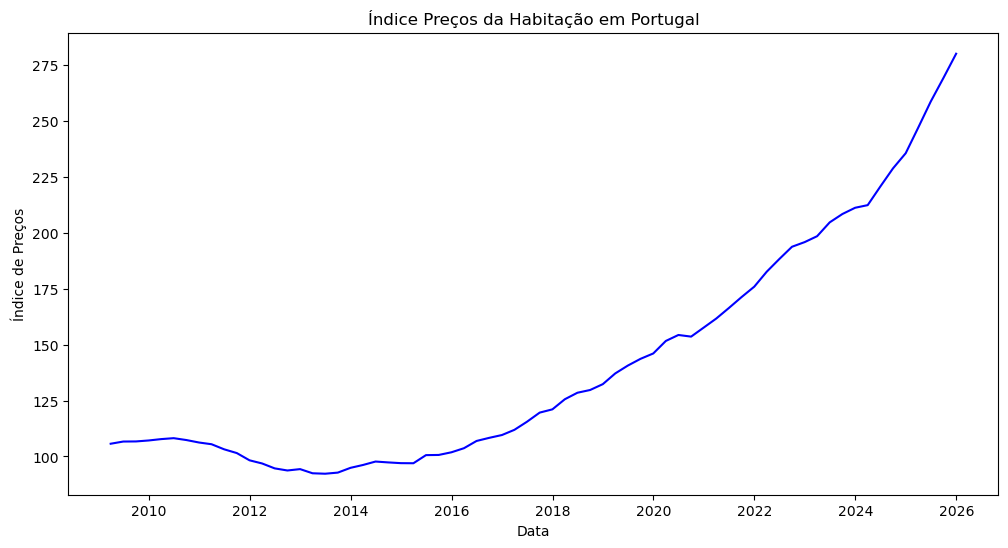

In [3]:
#Criar um gráfico da série em estudo 
plt.figure(figsize=(12,6)) #Definir a dimensão do gráfico
plt.plot(habitacional.index, habitacional['Índice de Preços'], color='blue')
plt.title('Índice Preços da Habitação em Portugal') #Definir o título do gráfico 
plt.xlabel('Data') #Definir o eixo horizontal 
plt.ylabel('Índice de Preços') #Definir o eixo vertical 

plt.show()

Tendência estimada: T(t) = 64.2276 + 2.3030 * t


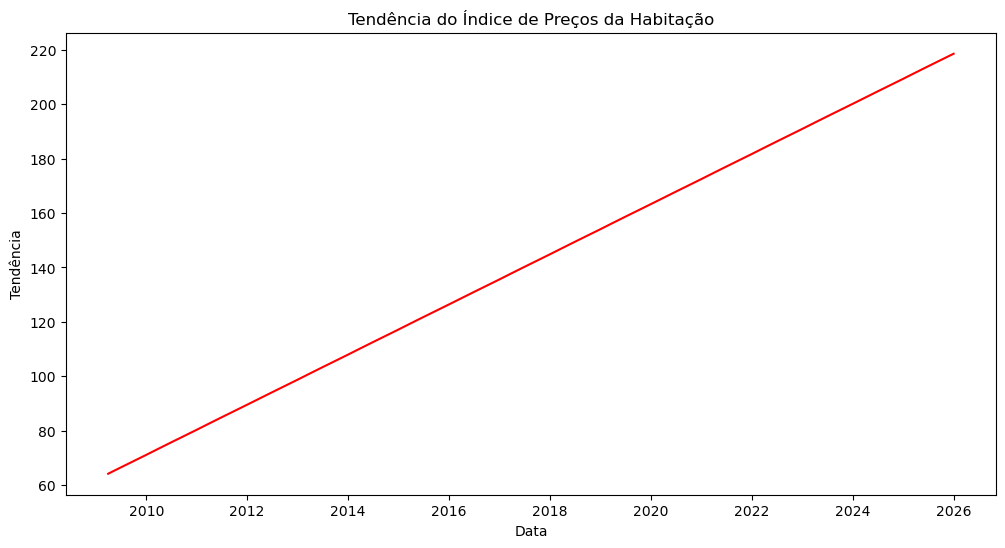

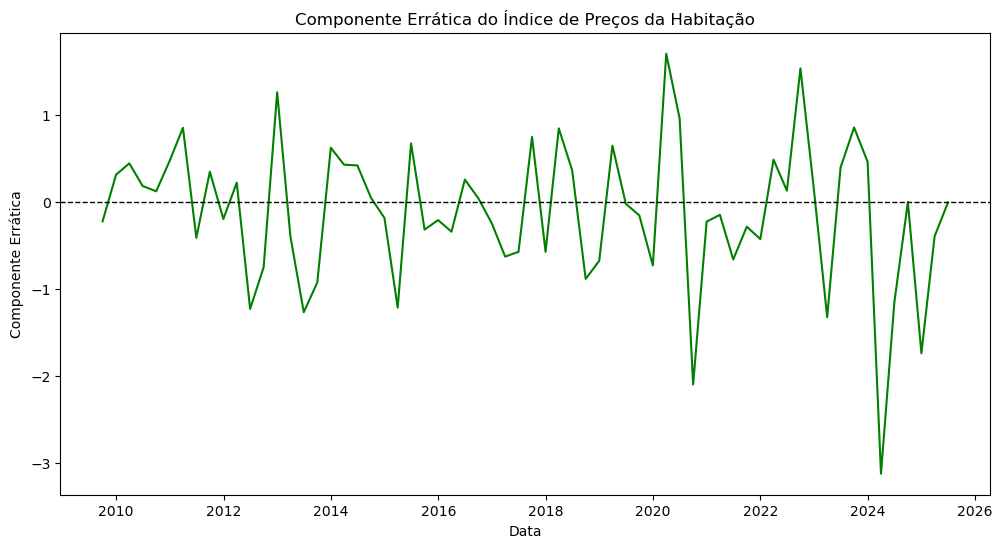

In [4]:
#Decompor a série temporal 
decomposicao= seasonal_decompose(habitacional['Índice de Preços'], model='additive', period=4)

#Criar o gráfico da tendência 
y = habitacional['Índice de Preços']
t = np.arange(len(y)).reshape(-1,1)
modelo_tendencia = LinearRegression().fit(t, y)
y_fit = modelo_tendencia.predict(t)
beta0 = modelo_tendencia.intercept_
beta1 = modelo_tendencia.coef_[0]

print(f"Tendência estimada: T(t) = {beta0:.4f} + {beta1:.4f} * t")
plt.figure(figsize=(12,6))
plt.plot(y.index,y_fit, color='red')
plt.title('Tendência do Índice de Preços da Habitação')
plt.xlabel('Data')
plt.ylabel('Tendência')

plt.show()

#Criar o gráfico da componente errática
plt.figure(figsize=(12,6))
plt.plot(decomposicao.resid, color='green')
plt.axhline(y=0, color='black', linestyle='--', linewidth=1)
plt.title('Componente Errática do Índice de Preços da Habitação')
plt.xlabel('Data')
plt.ylabel('Componente Errática')

plt.show()

df_decomposicao=pd.DataFrame({"Data":habitacional.index, "Tendencia":y_fit, "Erratica":decomposicao.resid})
df_decomposicao.set_index("Data", inplace=True)
df_decomposicao.to_excel("decomposicao_indice_habitacao.xlsx")

# Testes de raízes unitárias


===== Série Original =====

--- Teste ADF ---
Estatística de teste: 0.8890806657978775
p-value: 1.0
Valores críticos:
1%: -4.115412397821844
5%: -3.485092052154145
10%: -3.170590307779065


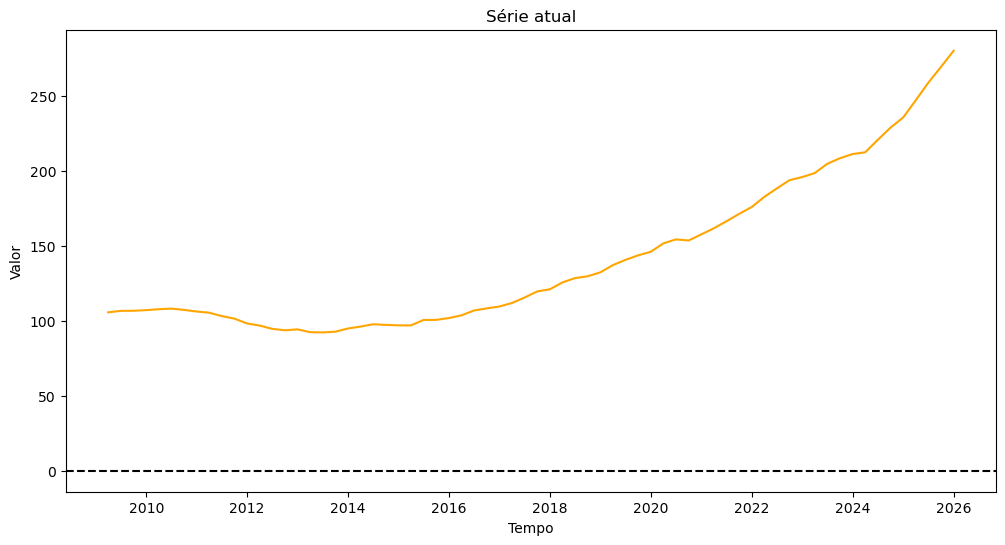


Não se rejeita a hipótese nula de presença de raiz unitária

===== Série em Log =====

--- Teste ADF ---
Estatística de teste: -1.1812539973065865
p-value: 0.914273941174093
Valores críticos:
1%: -4.10066975794895
5%: -3.478182141653062
10%: -3.166589815070338


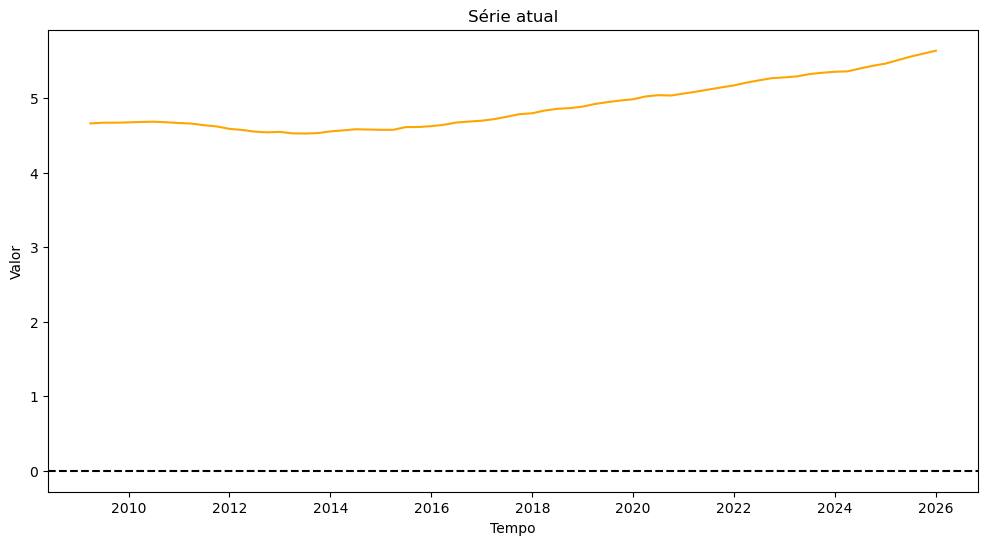


Não se rejeita a hipótese nula de presença de raiz unitária

--- Diferença 1 ---

--- Teste ADF ---
Estatística de teste: -5.594820721119391
p-value: 1.4925222094960453e-05
Valores críticos:
1%: -4.102930985196315
5%: -3.4792434170910203
10%: -3.167204658151766


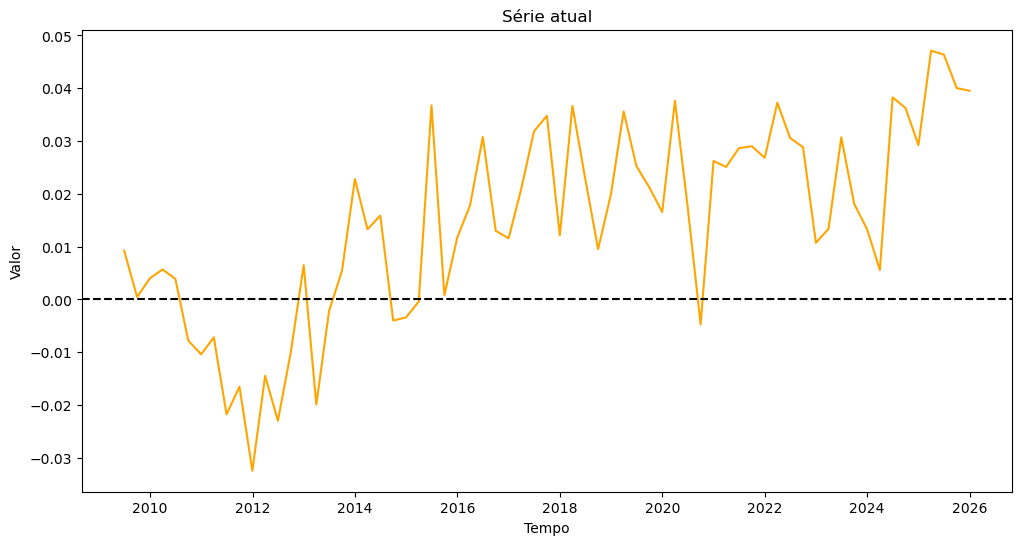


Rejeita-se a hipótese nula de presença de raiz unitária


In [5]:
# Teste ADF
serie_atual = habitacional.copy()

d = 0
log_aplicado = False

while True:
    
    resultado = adfuller(serie_atual.dropna(), regression='ct')
    
    if d == 0 and not log_aplicado:
        print("\n===== Série Original =====")
    elif log_aplicado and d == 0:
        print("\n===== Série em Log =====")
    else:
        print(f"\n--- Diferença {d} ---")
    
    # Resultados ADF
    print("\n--- Teste ADF ---")
    print("Estatística de teste:", resultado[0])
    print("p-value:", resultado[1])
    print("Valores críticos:")
    
    for key, value in resultado[4].items():
        print(f"{key}: {value}")
    
    # Gráfico
    plt.figure(figsize=(12,6))
    plt.plot(serie_atual, color='orange')
    plt.axhline(y=0, color='black', linestyle='--')
    plt.title("Série atual")
    plt.xlabel("Tempo")
    plt.ylabel("Valor")
    plt.show()
    
    # Critério de estacionaridade
    if resultado[1] <= 0.05:
        print("\nRejeita-se a hipótese nula de presença de raiz unitária")
        break
    else:
        print("\nNão se rejeita a hipótese nula de presença de raiz unitária")
    
    # Se ainda não aplicaste log, aplicas aqui antes de diferenciar
    if not log_aplicado:
        serie_atual = np.log(serie_atual)
        log_aplicado = True
        d = 0  # reinicia diferenças após log
    else:
        serie_atual = serie_atual.diff()
        d += 1

# Série final estacionária
y_estacionaria = serie_atual.dropna().copy()


===== Série Original =====

--- Teste Phillips-Perron ---
Estatística de teste: 2.0556450377817823
p-value: 1.0
Valores críticos:
1%: -4.10066975794895
5%: -3.478182141653062
10%: -3.166589815070338


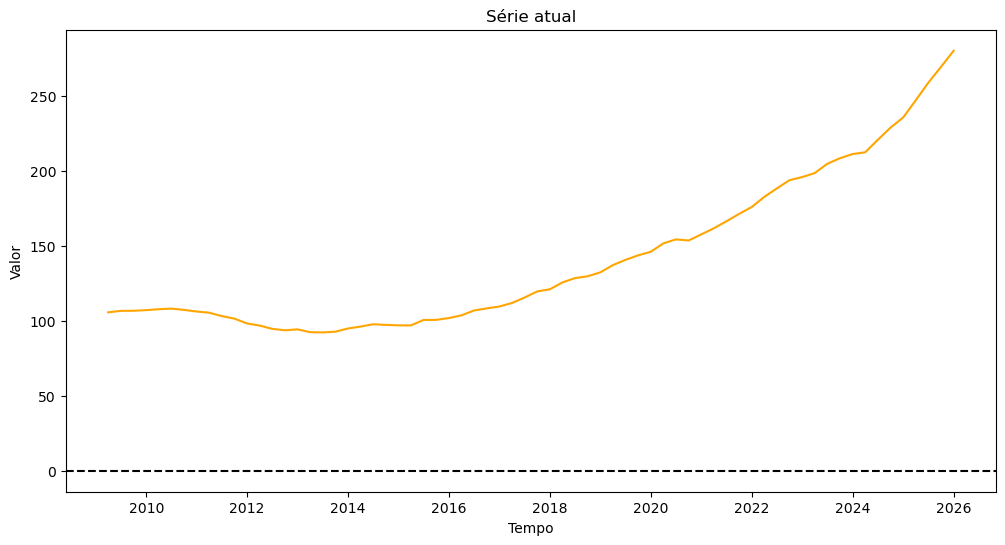


Não se rejeita a hipótese nula de presença de raiz unitária

===== Série em Log =====

--- Teste Phillips-Perron ---
Estatística de teste: -1.115207956020713
p-value: 0.9264831149061377
Valores críticos:
1%: -4.10066975794895
5%: -3.478182141653062
10%: -3.166589815070338


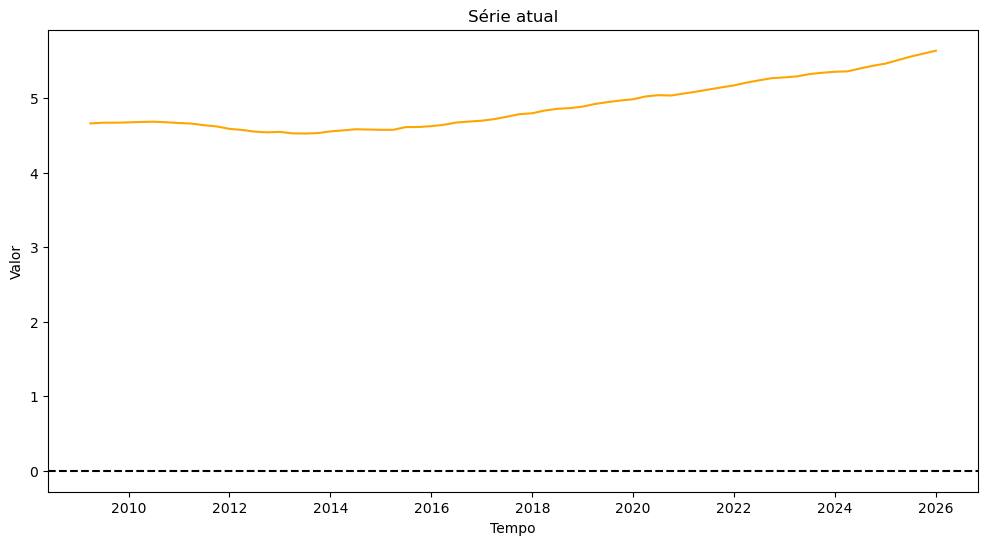


Não se rejeita a hipótese nula de presença de raiz unitária

--- Diferença 1 ---

--- Teste Phillips-Perron ---
Estatística de teste: -5.763576350859191
p-value: 6.7958188117673356e-06
Valores críticos:
1%: -4.102930985196315
5%: -3.4792434170910203
10%: -3.167204658151766


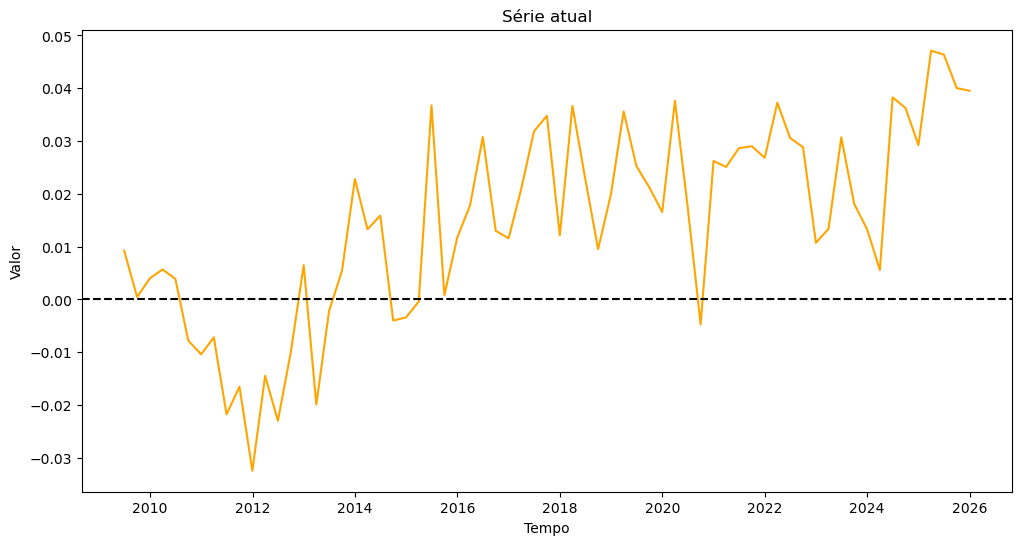


Rejeita-se a hipótese nula de presença de raiz unitária


In [6]:
#Teste PP
serie_atual = habitacional.copy()

d = 0
log_aplicado = False

while True:
    resultado = PhillipsPerron(serie_atual.dropna(), trend='ct')

    if d == 0 and not log_aplicado:
        print("\n===== Série Original =====")
    elif log_aplicado and d == 0:
        print("\n===== Série em Log =====")
    else:
        print(f"\n--- Diferença {d} ---")

    # Resultados do teste
    print("\n--- Teste Phillips-Perron ---")
    print("Estatística de teste:", resultado.stat)
    print("p-value:", resultado.pvalue)
    print("Valores críticos:")

    for key, value in resultado.critical_values.items():
        print(f"{key}: {value}")

    # Gráfico
    plt.figure(figsize=(12,6))
    plt.plot(serie_atual, color='orange')
    plt.axhline(y=0, color='black', linestyle='--')
    plt.title("Série atual")
    plt.xlabel("Tempo")
    plt.ylabel("Valor")
    plt.show()

    # Critério de estacionaridade
    if resultado.pvalue <= 0.05:
        print("\nRejeita-se a hipótese nula de presença de raiz unitária")
        break
    else:
        print("\nNão se rejeita a hipótese nula de presença de raiz unitária")

    # Aplicação sequencial das transformações
    if not log_aplicado:
        serie_atual = np.log(serie_atual)
        log_aplicado = True
        d = 0  # reinicia diferenciação após log
    else:
        serie_atual = serie_atual.diff()
        d += 1

# Série final estacionária
y_estacionaria = serie_atual.dropna().copy()

# Amostra de teste e de treino da variável dependente

In [7]:
#Amostra de treino e de teste da série em nível
y_treino=habitacional.iloc[:-20].asfreq('QE')
y_teste=habitacional.iloc[-20:].asfreq('QE')

log_habitacional=np.log(habitacional) #Logarimizar o índice de preços

#Amostra de treino e de teste da série logaritmizada
y_treino_log=log_habitacional.iloc[:-20].asfreq('QE')
y_teste_log=log_habitacional.iloc[-20:].asfreq('QE')

#Amostra de treino e de teste da série estacionária
y_treino_est=y_estacionaria.iloc[:-20].asfreq('QE')
y_teste_est=y_estacionaria.iloc[-20:].asfreq('QE')

#Criar as dummys
dummys=pd.DataFrame(index=log_habitacional.index)
dummys["crises"]=(((dummys.index <= "2013-06-30") & (dummys.index >= "2010-09-30"))).astype(int) 

#Amostra de treino e de teste das dummys
dummys_treino_crises = dummys["crises"].iloc[:-20].asfreq('QE')
dummys_teste_crises = dummys["crises"].iloc[-20:].asfreq('QE')

df_temp = y_treino_log.join(dummys_treino_crises, how="inner").dropna()

y_treino_log_alinhado = df_temp.iloc[:, 0]
x_treino_dummy = df_temp.iloc[:, 1:]


# ARIMA

    Lag        AC       PAC      Q-Stat          Prob
0     1  0.595969  0.608925   17.782136  2.476980e-05
1     2  0.551027  0.325371   33.321271  5.812700e-08
2     3  0.554054  0.279565   49.388679  1.078150e-10
3     4  0.585726  0.307595   67.763105  6.730145e-14
4     5  0.440027 -0.074850   78.380144  1.830670e-15
5     6  0.358260 -0.156364   85.589689  2.491596e-16
6     7  0.370873 -0.005666   93.508947  2.350219e-17
7     8  0.309432 -0.093429   99.163015  6.329428e-18
8     9  0.172713 -0.237392  100.970864  1.001006e-17
9    10  0.155843 -0.048914  102.482574  1.733862e-17
10   11  0.205446  0.176703  105.182712  1.671711e-17
11   12  0.039407 -0.260415  105.284893  5.100383e-17
12   13  0.030478  0.055513  105.347815  1.515087e-16
13   14  0.007623 -0.004212  105.351870  4.434570e-16
14   15  0.072940  0.177104  105.734763  1.057547e-15
15   16 -0.086650 -0.225074  106.292547  2.263199e-15
16   17 -0.137995 -0.261589  107.754390  3.187377e-15
17   18 -0.201284 -0.583322 

(0.5, 20.0)

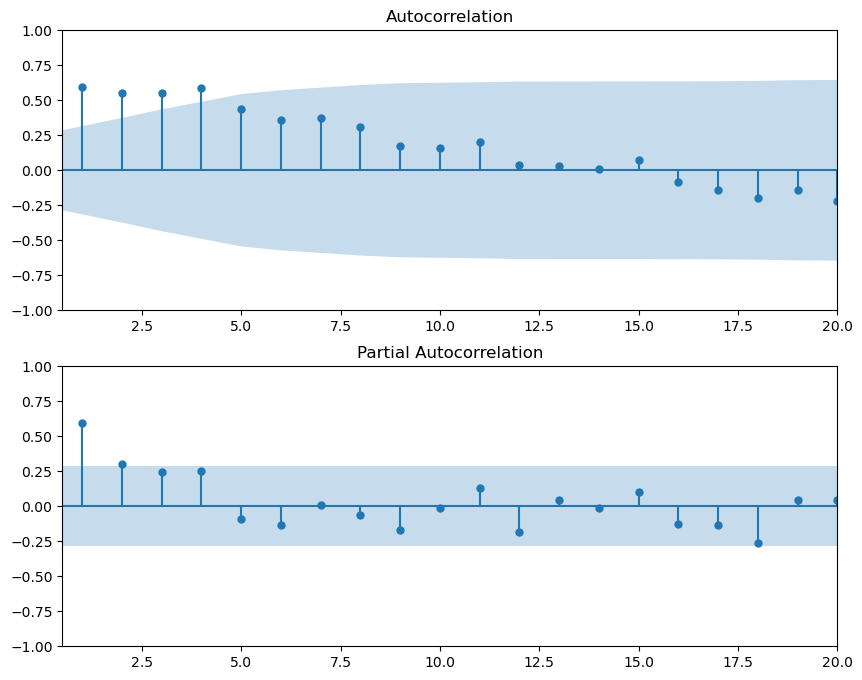

In [8]:
lags = 20

# ACF e PACF
acf_vals = acf(y_treino_est, nlags=lags)
pacf_vals = pacf(y_treino_est, nlags=lags)

# Ljung-Box
ljung = acorr_ljungbox(y_treino_est, lags=lags, return_df=True)

# Criar tabela
correlograma = pd.DataFrame({
    "Lag": range(1,lags+1),
    "AC": acf_vals[1:lags+1],
    "PAC": pacf_vals[1:lags+1],
    "Q-Stat": ljung["lb_stat"].values,
    "Prob": ljung["lb_pvalue"].values
})

print(correlograma)

fig, ax = plt.subplots(2, 1, figsize=(10,8))

plot_acf(y_treino_est, lags=20, ax=ax[0])
ax[0].set_xlim(0.5, 20)

plot_pacf(y_treino_est, lags=20, method='ywm', ax=ax[1])
ax[1].set_xlim(0.5, 20)

In [9]:
#Determinar quais os 5 melhores ARIMA's
p=range(0,5)
d=[1]
q=range(0,5)

parametros_arima = list(product(p,d,q))
resultados_arimas = []
previsoes_modelos_arimas = {}

for param in parametros_arima:
    try:
        modelo_arima = ARIMA(y_treino_log_alinhado, exog= x_treino_dummy, order=param, trend='t').fit()
        convergiu= modelo_arima.mle_retvals.get("converged",False)

        if not convergiu:
            continue
        else:
            print(modelo_arima.summary())
    except:
        continue
    

    #Previsão para a amostra de teste
    previsao_teste_arima_log = modelo_arima.forecast(steps=len(y_teste_log), exog=dummys_teste_crises)
    previsao_teste_arima=np.exp(previsao_teste_arima_log)
    y_teste_original = np.exp(y_teste_log)
    eqm_teste_arima = mean_squared_error(y_teste_original, previsao_teste_arima)
    epam_teste_arima = mean_absolute_percentage_error(y_teste_original, previsao_teste_arima)
    aic_teste_arima = modelo_arima.aic

    resultados_arimas.append({
        "p": param[0],
        "d": param[1],
        "q": param[2],
        "AIC": aic_teste_arima,
        "EQM": eqm_teste_arima,
        "EPAM": epam_teste_arima,
    })

    previsoes_modelos_arimas[param] = previsao_teste_arima

# Criar DataFrame de resultados e selecionar top 5 pelo AIC
df_resultados_arimas = pd.DataFrame(resultados_arimas)
df_resultados_arimas = df_resultados_arimas.sort_values(by="AIC")
top5_arimas = df_resultados_arimas.head(5)

# Preparar DataFrame final de previsões
df_previsoes_arimas = pd.DataFrame(index=y_teste_log.index)

# Colocar os parâmetros (p,d,q) na primeira linha
parametros_linhas = []
for i, row in top5_arimas.iterrows():
    param = (row['p'], row['d'], row['q'])
    df_previsoes_arimas[f"ARIMA{param}"] = previsoes_modelos_arimas[param].values
    parametros_linhas.append(str(param))  # guardar string para primeira linha

# Adicionar coluna com reais
df_previsoes_arimas["Real"] = np.exp(y_teste_log.values)
parametros_linhas.append("Real")  # adicionar também para os reais

# Criar DataFrame final com primeira linha como parâmetros
df_final = pd.DataFrame(columns=df_previsoes_arimas.columns)
df_final.loc[0] = parametros_linhas  # primeira linha com (p,d,q)
df_final = pd.concat([df_final, df_previsoes_arimas], ignore_index=True)

# Guardar as previsões da amostra de teste
df_final.to_excel("Resultados_ARIMAS.xlsx", sheet_name="Previsoes_Teste", index=True)

print("Top 5 ARIMA:")
print(top5_arimas)

                               SARIMAX Results                                
Dep. Variable:       Índice de Preços   No. Observations:                   48
Model:                 ARIMA(0, 1, 0)   Log Likelihood                 123.688
Date:                Wed, 16 Sep 2026   AIC                           -241.376
Time:                        14:14:31   BIC                           -235.826
Sample:                    03-31-2009   HQIC                          -239.287
                         - 12-31-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
drift          0.0085      0.003      3.301      0.001       0.003       0.014
crises        -0.0066      0.022     -0.299      0.765      -0.050       0.037
sigma2         0.0003   7.64e-05      3.966      0.0

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:       Índice de Preços   No. Observations:                   48
Model:                 ARIMA(0, 1, 4)   Log Likelihood                 136.311
Date:                Wed, 16 Sep 2026   AIC                           -258.623
Time:                        14:14:31   BIC                           -245.672
Sample:                    03-31-2009   HQIC                          -253.749
                         - 12-31-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
drift          0.0088      0.005      1.896      0.058      -0.000       0.018
crises        -0.0026      0.012     -0.215      0.830      -0.026       0.021
ma.L1          0.3299      0.180      1.829      0.0

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:       Índice de Preços   No. Observations:                   48
Model:                 ARIMA(1, 1, 3)   Log Likelihood                 138.499
Date:                Wed, 16 Sep 2026   AIC                           -262.997
Time:                        14:14:32   BIC                           -250.046
Sample:                    03-31-2009   HQIC                          -258.124
                         - 12-31-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
drift          0.0089      0.008      1.065      0.287      -0.007       0.025
crises        -0.0011      0.011     -0.095      0.924      -0.023       0.021
ar.L1          0.8631      0.117      7.405      0.0

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


... (2 outputs left out)

                               SARIMAX Results                                
Dep. Variable:       Índice de Preços   No. Observations:                   48
Model:                 ARIMA(3, 1, 4)   Log Likelihood                 140.477
Date:                Wed, 16 Sep 2026   AIC                           -260.954
Time:                        14:14:33   BIC                           -242.452
Sample:                    03-31-2009   HQIC                          -253.992
                         - 12-31-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
drift          0.0092      0.009      1.009      0.313      -0.009       0.027
crises        -0.0032      0.011     -0.291      0.771      -0.025       0.018
ar.L1          0.5516      0.427      1.293      0.1

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Top 5 ARIMA:
    p  d  q         AIC          EQM      EPAM
12  4  1  0 -264.761308  1050.683442  0.112113
5   1  1  3 -262.997206  1648.856817  0.145199
10  3  1  0 -262.796814  1529.747261  0.139214
7   2  1  1 -262.176497   706.653280  0.091951
6   2  1  0 -262.140256  1649.857623  0.144748


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


# Importação das variáveis exógenas

In [10]:
#Importar os dados para as variáveis exógenas
exog=pd.read_excel("TFM - Catarina Caleiro.xlsx",sheet_name="Dados", header=1, usecols='C:L')

#Renomear as colunas
exog.columns=['PIB Real', 'Índice de preços no consumidor (2025=100)', 'Índice de custos de construção de habitação nova (2021=100)',
             'Taxa de juro (TAA) de novas operações de empréstimos à habitação (%)','População empregada','Fogos concluidos em construções novas para habitação',
             'Nº de edifícios licenciados', 'Indicador Coincidente para a atividade económica',
             'Indicador de confiança da construção e obras públicas',
             'Perspetivas de atividade nos próximos 3 meses em construção e obras públicas']

#Eliminar NaN
exog.dropna(inplace=True)


# Utilizar o mesmo índice do DataFrame habitacional
exog.index = habitacional.index

#Criar um Dataframe com todos os dados
dados_completos=habitacional.join(exog, how="inner").dropna() #juntar todos os dados num só dataframe

#Remover colunas duplicadas
if 'Data' in exog.columns:
        exog.drop(columns=['Data'], inplace=True)

exog.dropna(inplace=True)
exog.head()


,PIB Real,Índice de preços no consumidor (2025=100),Índice de custos de construção de habitação nova (2021=100),Taxa de juro (TAA) de novas operações de empréstimos à habitação (%),População empregada,Fogos concluidos em construções novas para habitação,Nº de edifícios licenciados,Indicador Coincidente para a atividade económica,Indicador de confiança da construção e obras públicas,Perspetivas de atividade nos próximos 3 meses em construção e obras públicas
Data,,,,,,,,,,
2009-03-31,51268.9,74.518333,79.263333,3.550000,4593.033333,11784.0,2632.666667,-3.033333,-29.500000,-13.2
2009-06-30,51324.0,75.006667,79.393333,2.676667,4554.066667,12021.0,2685.333333,-2.766667,-24.466667,-10.2
2009-09-30,51762.7,74.500667,79.906667,2.416667,4503.766667,12573.0,2622.333333,-1.600000,-24.500000,-7.8
2009-12-31,51800.9,74.700667,80.113333,2.263333,4501.933333,11537.0,2390.666667,-0.400000,-26.800000,-10.0
2010-03-31,52262.1,74.738667,79.896667,2.200000,4507.766667,8994.0,2401.333333,0.866667,-31.333333,-14.5


# Teste de raiz unitária das variáveis exógenas


================ PIB Real ================


===== NÍVEL =====


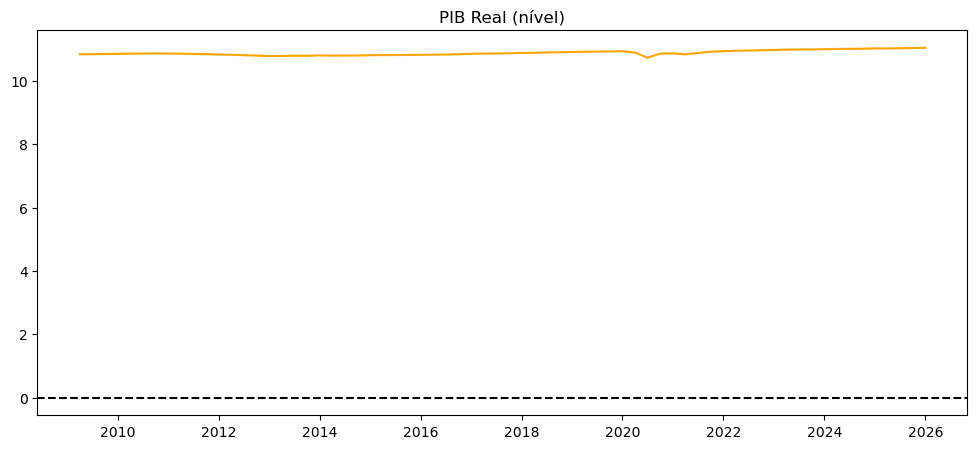


--- ADF ---
Estatística: -2.5676580173976142
p-value: 0.29500055729692465
Valores críticos:
  1%: -4.10066975794895
  5%: -3.478182141653062
  10%: -3.166589815070338

--- PP ---
Estatística: -2.355617143125449
p-value: 0.40346438832082504
Valores críticos:
  1%: -4.10066975794895
  5%: -3.478182141653062
  10%: -3.166589815070338

===== 1ª DIFERENÇA =====


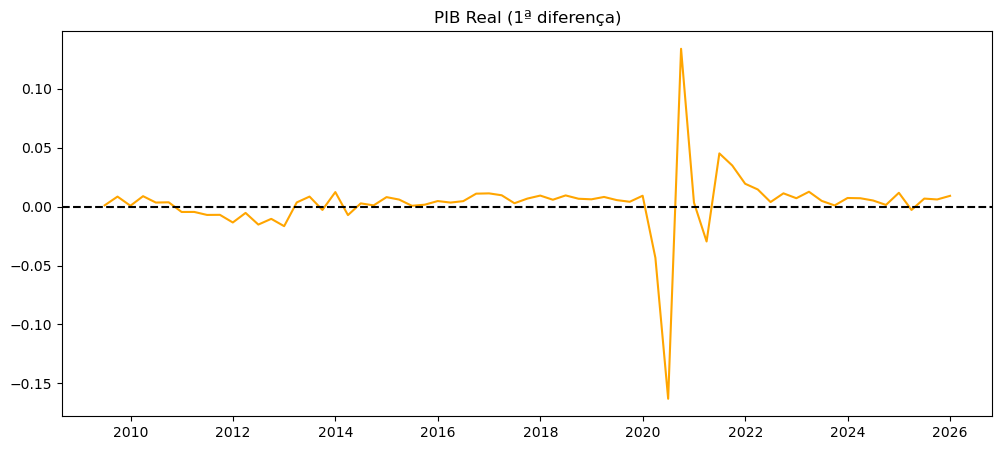


--- ADF ---
Estatística: -8.14450295460585
p-value: 3.311249922817808e-11
Valores críticos:
  1%: -4.105265484751935
  5%: -3.4803385352753753
  10%: -3.1678389485662266

--- PP ---
Estatística: -12.032028703364146
p-value: 3.411139166271208e-19
Valores críticos:
  1%: -4.102930985196315
  5%: -3.4792434170910203
  10%: -3.167204658151766

================ Índice de preços no consumidor (2025=100) ================


===== NÍVEL =====


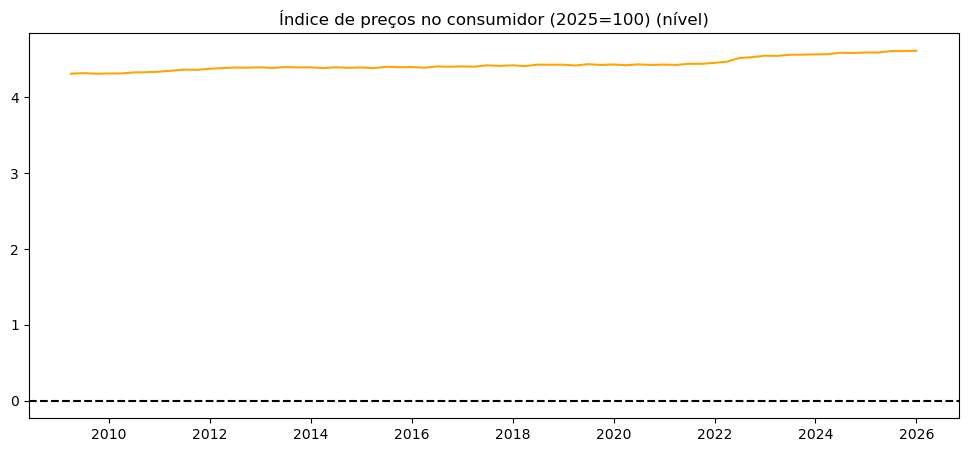


--- ADF ---
Estatística: -0.9545267663802773
p-value: 0.9499325611325042
Valores críticos:
  1%: -4.123996164459387
  5%: -3.4891051933248596
  10%: -3.172910779449752

--- PP ---
Estatística: -1.1534543600917486
p-value: 0.9196133722899877
Valores críticos:
  1%: -4.10066975794895
  5%: -3.478182141653062
  10%: -3.166589815070338

===== 1ª DIFERENÇA =====


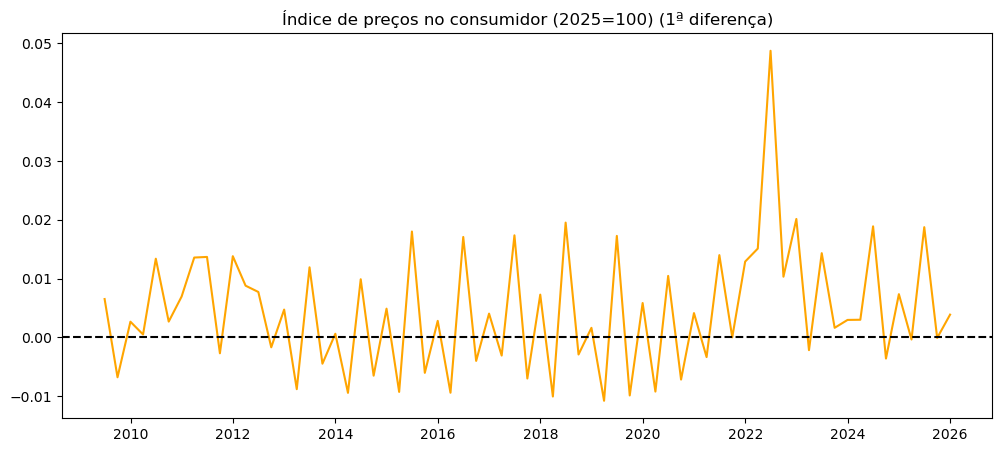


--- ADF ---
Estatística: -2.840882823988833
p-value: 0.18233407355632325
Valores críticos:
  1%: -4.123996164459387
  5%: -3.4891051933248596
  10%: -3.172910779449752

--- PP ---
Estatística: -10.094755348883922
p-value: 1.4558407403303565e-15
Valores críticos:
  1%: -4.102930985196315
  5%: -3.4792434170910203
  10%: -3.167204658151766

===== 2ª DIFERENÇA =====


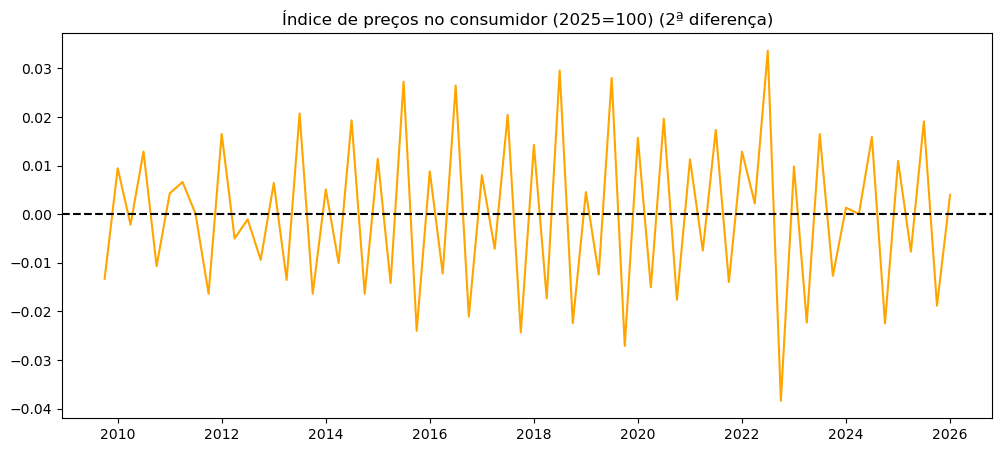


--- ADF ---
Estatística: -3.812762036545906
p-value: 0.015925688710105322
Valores críticos:
  1%: -4.133575845229151
  5%: -3.4935752832456797
  10%: -3.1754929451540197

--- PP ---
Estatística: -44.12892982451173
p-value: 0.0
Valores críticos:
  1%: -4.105265484751935
  5%: -3.4803385352753753
  10%: -3.1678389485662266

================ Índice de custos de construção de habitação nova (2021=100) ================


===== NÍVEL =====


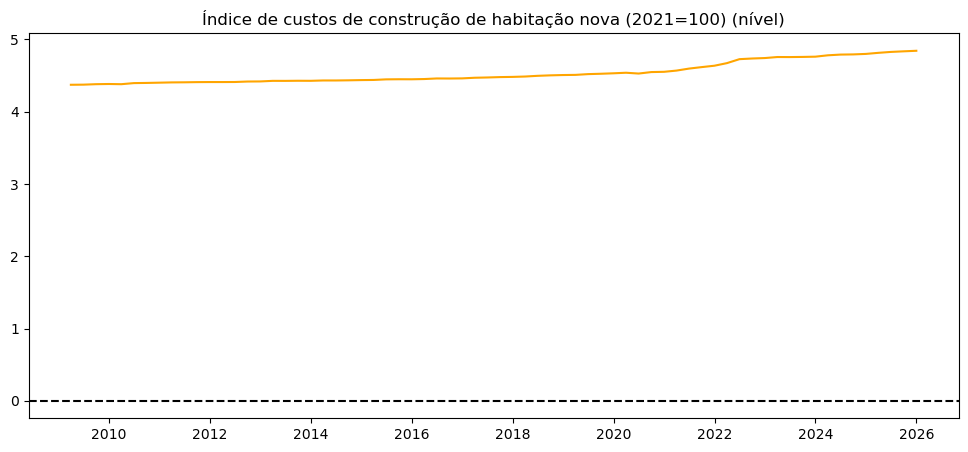


--- ADF ---
Estatística: -0.8502356354305077
p-value: 0.9611815388678882
Valores críticos:
  1%: -4.102930985196315
  5%: -3.4792434170910203
  10%: -3.167204658151766

--- PP ---
Estatística: -0.783608013704689
p-value: 0.9670362231053994
Valores críticos:
  1%: -4.10066975794895
  5%: -3.478182141653062
  10%: -3.166589815070338

===== 1ª DIFERENÇA =====


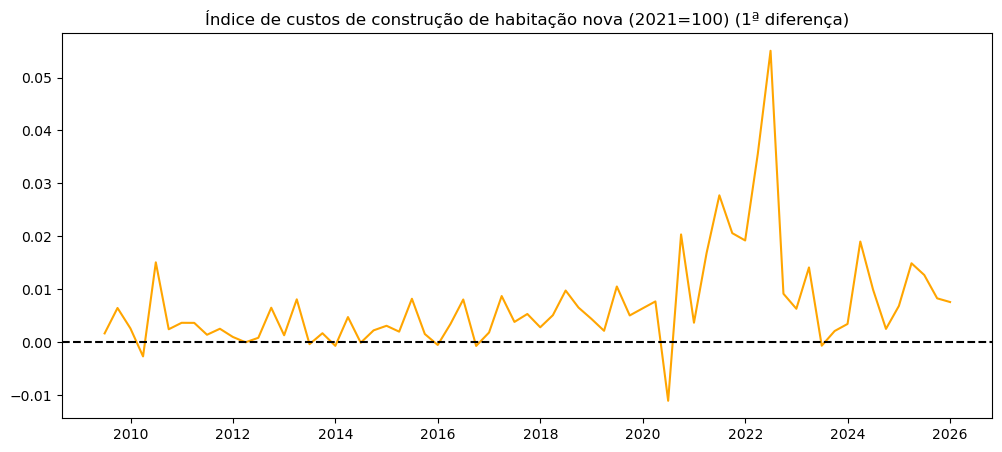


--- ADF ---
Estatística: -5.686046236555737
p-value: 9.77528182369476e-06
Valores críticos:
  1%: -4.102930985196315
  5%: -3.4792434170910203
  10%: -3.167204658151766

--- PP ---
Estatística: -5.708438684399026
p-value: 8.8040859394304e-06
Valores críticos:
  1%: -4.102930985196315
  5%: -3.4792434170910203
  10%: -3.167204658151766

================ Taxa de juro (TAA) de novas operações de empréstimos à habitação (%) ================


===== NÍVEL =====


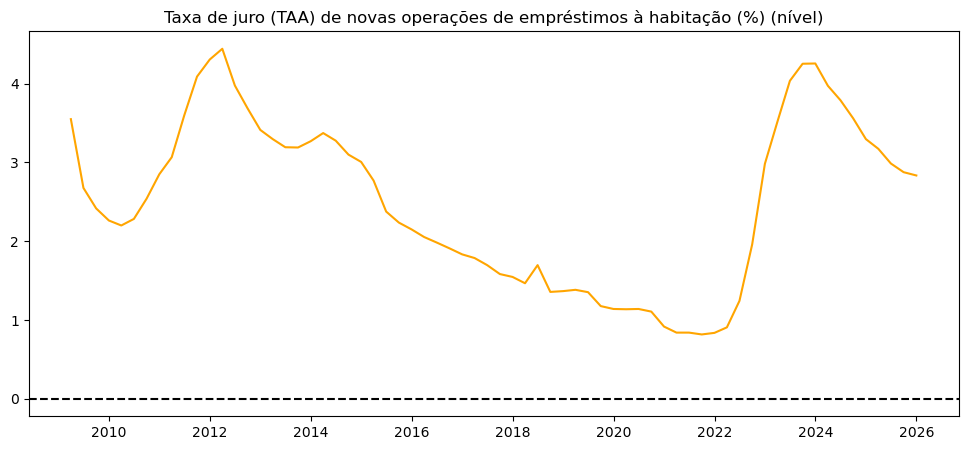


--- ADF ---
Estatística: -2.389646327942581
p-value: 0.14468000536843034
Valores críticos:
  1%: -3.5335601309235605
  5%: -2.9064436883991434
  10%: -2.590723948576676

--- PP ---
Estatística: -1.8076937152175416
p-value: 0.37664872314444425
Valores críticos:
  1%: -3.5319549603840894
  5%: -2.905755128523123
  10%: -2.5903569458676765

===== 1ª DIFERENÇA =====


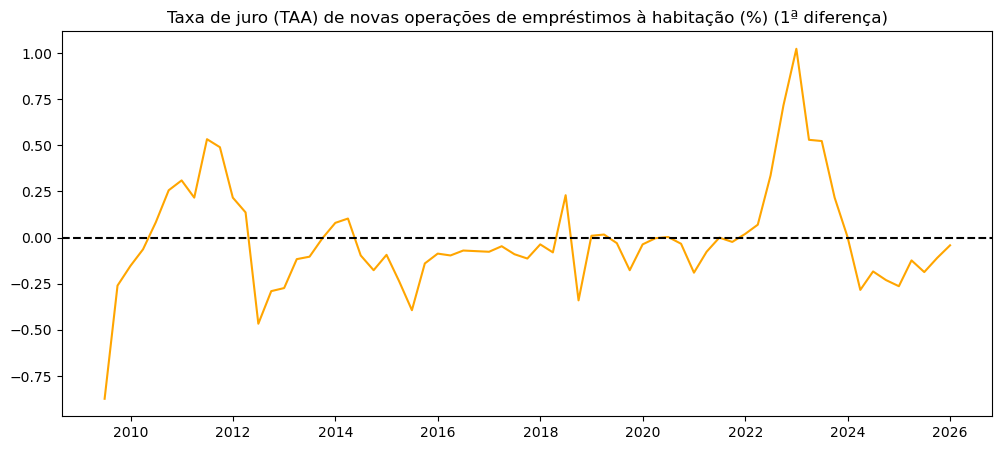


--- ADF ---
Estatística: -3.5223662883869338
p-value: 0.007430920375542349
Valores críticos:
  1%: -3.53692771987915
  5%: -2.907887369384766
  10%: -2.591493291015625

--- PP ---
Estatística: -4.2094116980120395
p-value: 0.0006351416614445737
Valores críticos:
  1%: -3.5335601309235605
  5%: -2.9064436883991434
  10%: -2.590723948576676

================ População empregada ================


===== NÍVEL =====


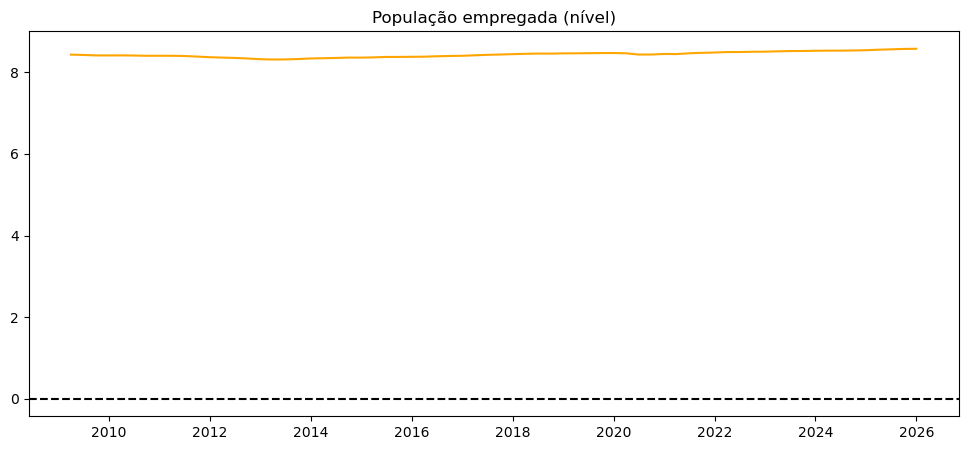


--- ADF ---
Estatística: -3.4876105738115735
p-value: 0.040735970979301074
Valores críticos:
  1%: -4.118172754629629
  5%: -3.486383398148148
  10%: -3.1713372222222223

--- PP ---
Estatística: -2.3178828895052144
p-value: 0.42408477836080427
Valores críticos:
  1%: -4.10066975794895
  5%: -3.478182141653062
  10%: -3.166589815070338

===== 1ª DIFERENÇA =====


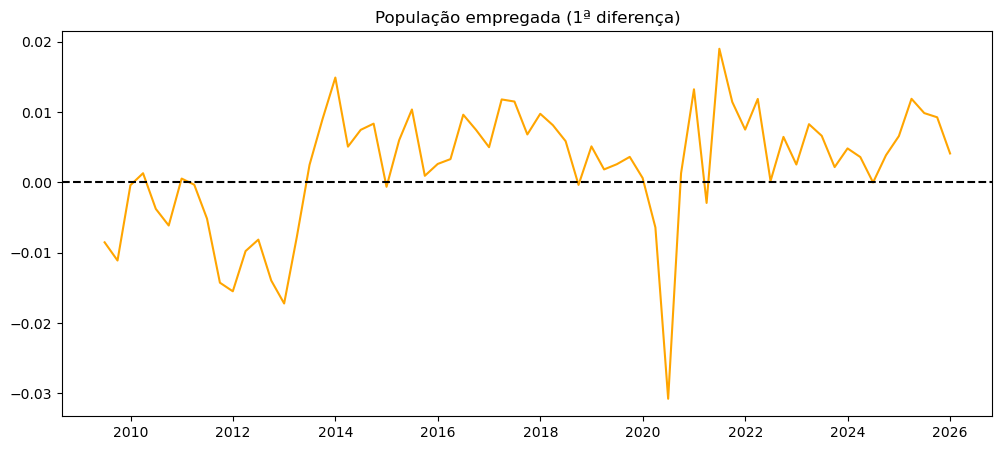


--- ADF ---
Estatística: -4.715158738051667
p-value: 0.0006573785125458622
Valores críticos:
  1%: -4.102930985196315
  5%: -3.4792434170910203
  10%: -3.167204658151766

--- PP ---
Estatística: -4.619517477364521
p-value: 0.0009561191567922982
Valores críticos:
  1%: -4.102930985196315
  5%: -3.4792434170910203
  10%: -3.167204658151766

================ Fogos concluidos em construções novas para habitação ================


===== NÍVEL =====


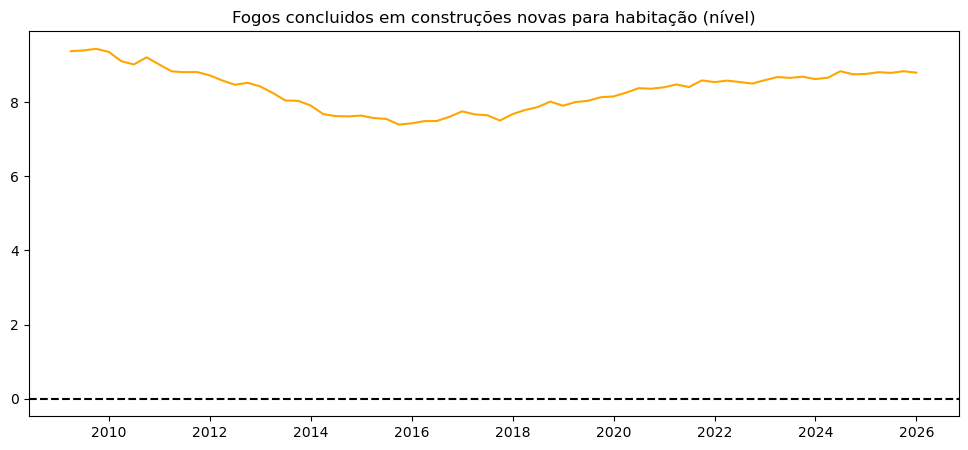


--- ADF ---
Estatística: -3.158847686976679
p-value: 0.022493766667917157
Valores críticos:
  1%: -3.548493559596539
  5%: -2.912836594776334
  10%: -2.594129155766944

--- PP ---
Estatística: -1.8538296462264525
p-value: 0.35408282481436515
Valores críticos:
  1%: -3.5319549603840894
  5%: -2.905755128523123
  10%: -2.5903569458676765

===== 1ª DIFERENÇA =====


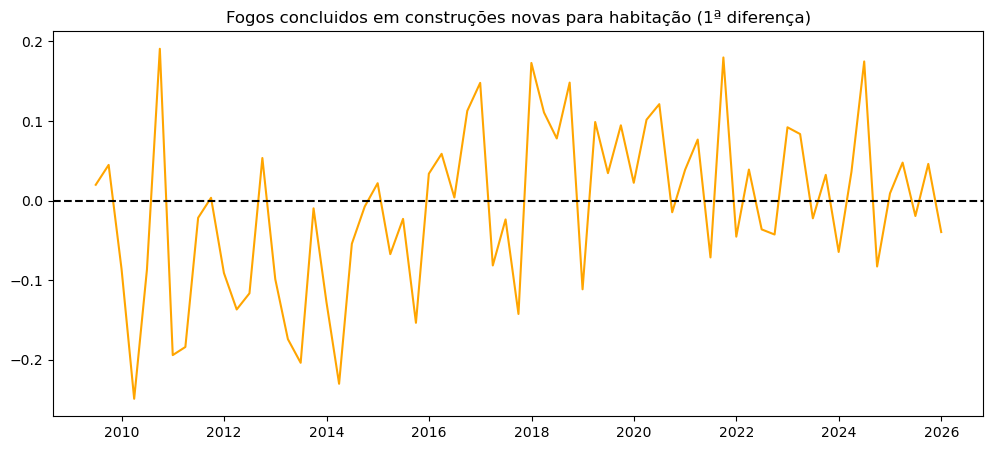


--- ADF ---
Estatística: -1.572527514630115
p-value: 0.49737746642230707
Valores críticos:
  1%: -3.552928203580539
  5%: -2.9147306250000002
  10%: -2.595137155612245

--- PP ---
Estatística: -7.908415159862861
p-value: 4.008356915352045e-12
Valores críticos:
  1%: -3.5335601309235605
  5%: -2.9064436883991434
  10%: -2.590723948576676

===== 2ª DIFERENÇA =====


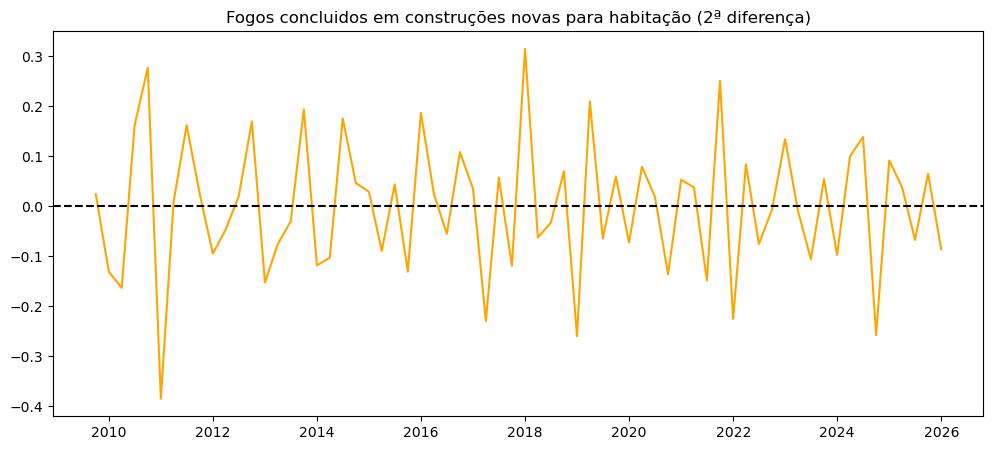


--- ADF ---
Estatística: -2.192742518690163
p-value: 0.2088900407866992
Valores críticos:
  1%: -3.552928203580539
  5%: -2.9147306250000002
  10%: -2.595137155612245

--- PP ---
Estatística: -24.893884449573132
p-value: 0.0
Valores críticos:
  1%: -3.5352168748293127
  5%: -2.9071540828402367
  10%: -2.5911025443786984

===== 3ª DIFERENÇA =====


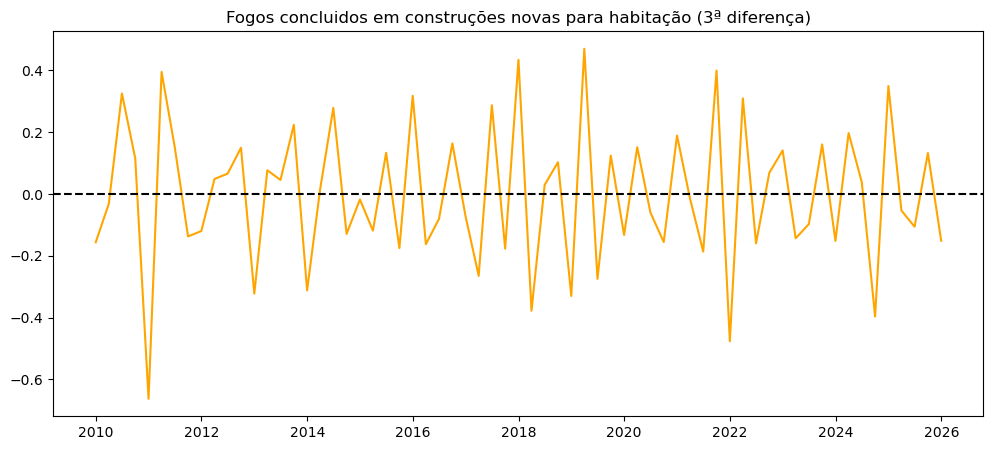


--- ADF ---
Estatística: -7.935488998750379
p-value: 3.4225568067906824e-12
Valores críticos:
  1%: -3.552928203580539
  5%: -2.9147306250000002
  10%: -2.595137155612245

--- PP ---
Estatística: -47.025192155567574
p-value: 0.0
Valores críticos:
  1%: -3.53692771987915
  5%: -2.907887369384766
  10%: -2.591493291015625

================ Nº de edifícios licenciados ================


===== NÍVEL =====


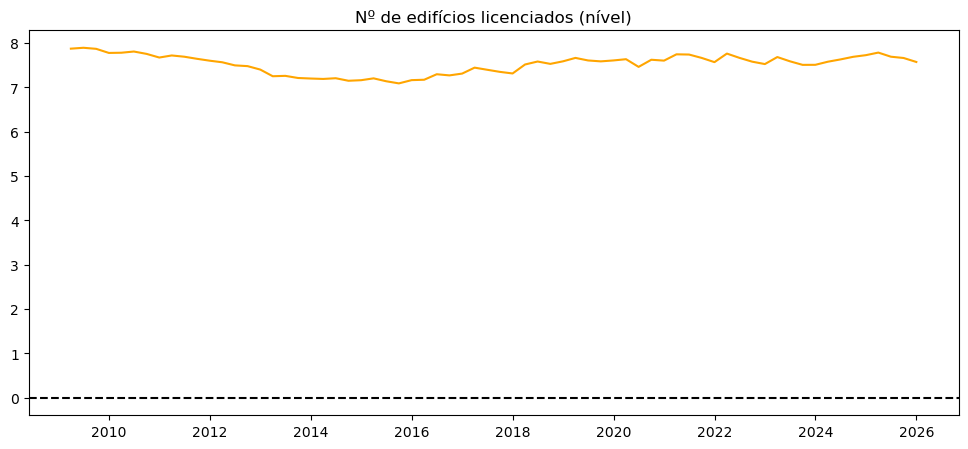


--- ADF ---
Estatística: -2.0444805393332732
p-value: 0.2674166996973539
Valores críticos:
  1%: -3.5386953618719676
  5%: -2.9086446751210775
  10%: -2.591896782564878

--- PP ---
Estatística: -2.0827689510896494
p-value: 0.2514994996716186
Valores críticos:
  1%: -3.5319549603840894
  5%: -2.905755128523123
  10%: -2.5903569458676765

===== 1ª DIFERENÇA =====


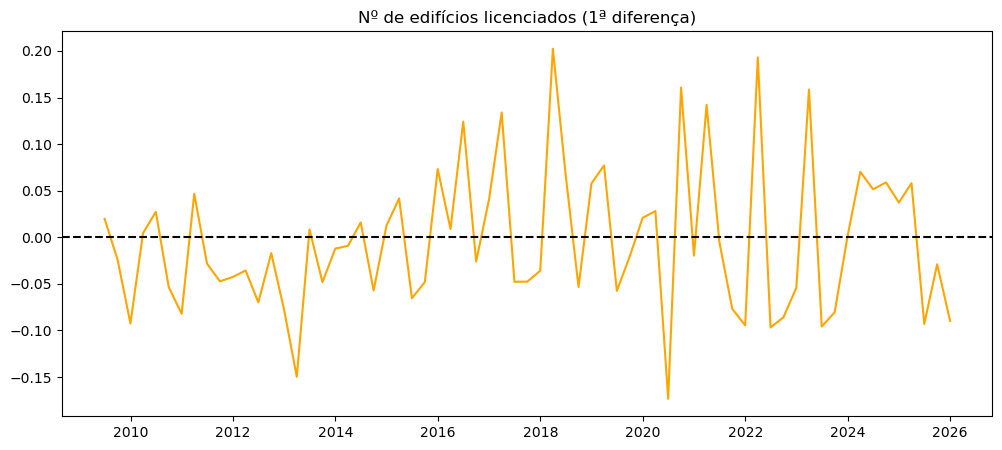


--- ADF ---
Estatística: -2.7326768365706577
p-value: 0.06855241775504645
Valores críticos:
  1%: -3.5386953618719676
  5%: -2.9086446751210775
  10%: -2.591896782564878

--- PP ---
Estatística: -8.865311104424553
p-value: 1.4457952013830276e-14
Valores críticos:
  1%: -3.5335601309235605
  5%: -2.9064436883991434
  10%: -2.590723948576676

===== 2ª DIFERENÇA =====


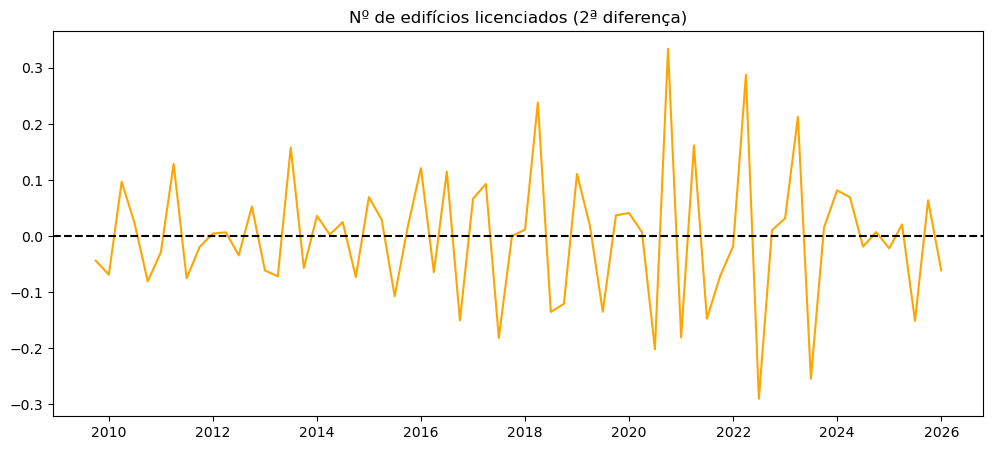


--- ADF ---
Estatística: -11.465153708235578
p-value: 5.433740976969116e-21
Valores críticos:
  1%: -3.5386953618719676
  5%: -2.9086446751210775
  10%: -2.591896782564878

--- PP ---
Estatística: -32.067318373713775
p-value: 0.0
Valores críticos:
  1%: -3.5352168748293127
  5%: -2.9071540828402367
  10%: -2.5911025443786984

================ Indicador Coincidente para a atividade económica ================


===== NÍVEL =====


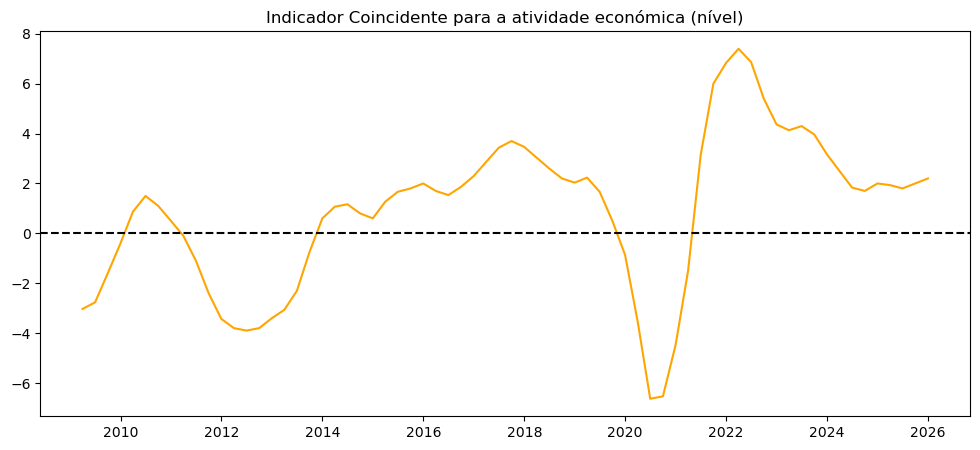


--- ADF ---
Estatística: -2.9406033791804673
p-value: 0.040826026933291945
Valores críticos:
  1%: -3.540522678829176
  5%: -2.9094272025108254
  10%: -2.5923136524453696

--- PP ---
Estatística: -2.0110125417308753
p-value: 0.2817654563607702
Valores críticos:
  1%: -3.5319549603840894
  5%: -2.905755128523123
  10%: -2.5903569458676765

===== 1ª DIFERENÇA =====


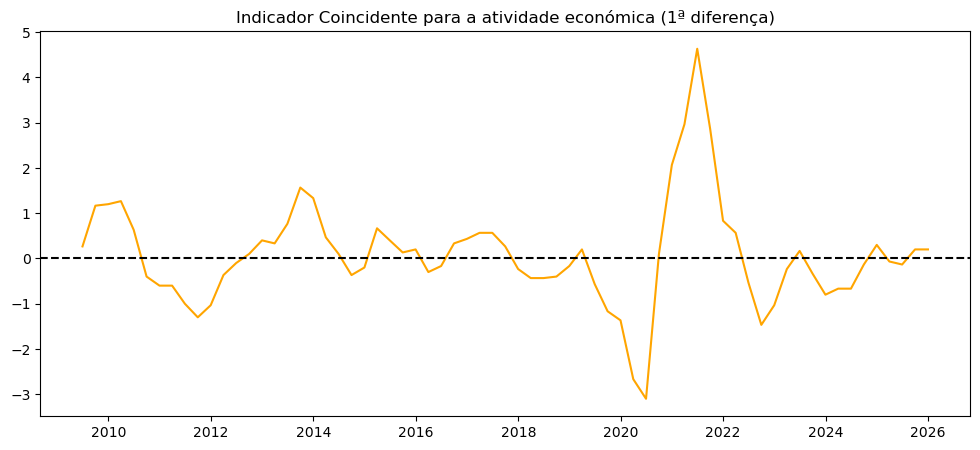


--- ADF ---
Estatística: -3.9523701353047342
p-value: 0.0016815115907280608
Valores críticos:
  1%: -3.5463945337644063
  5%: -2.911939409384601
  10%: -2.5936515282964665

--- PP ---
Estatística: -2.269997510228586
p-value: 0.18182698942775227
Valores críticos:
  1%: -3.5335601309235605
  5%: -2.9064436883991434
  10%: -2.590723948576676

===== 2ª DIFERENÇA =====


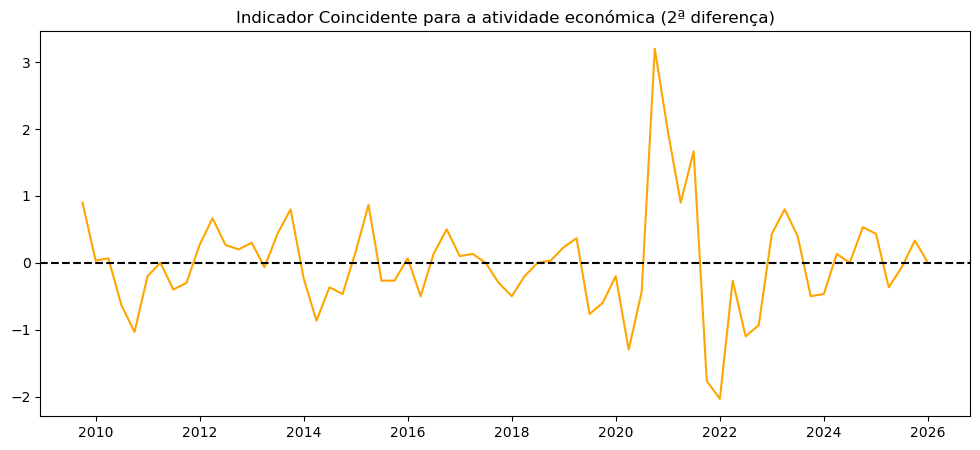


--- ADF ---
Estatística: -4.337154789086504
p-value: 0.0003828116516865247
Valores críticos:
  1%: -3.55770911573439
  5%: -2.9167703434435808
  10%: -2.59622219478738

--- PP ---
Estatística: -5.194873245646858
p-value: 9.006465524230538e-06
Valores críticos:
  1%: -3.5352168748293127
  5%: -2.9071540828402367
  10%: -2.5911025443786984

================ Indicador de confiança da construção e obras públicas ================


===== NÍVEL =====


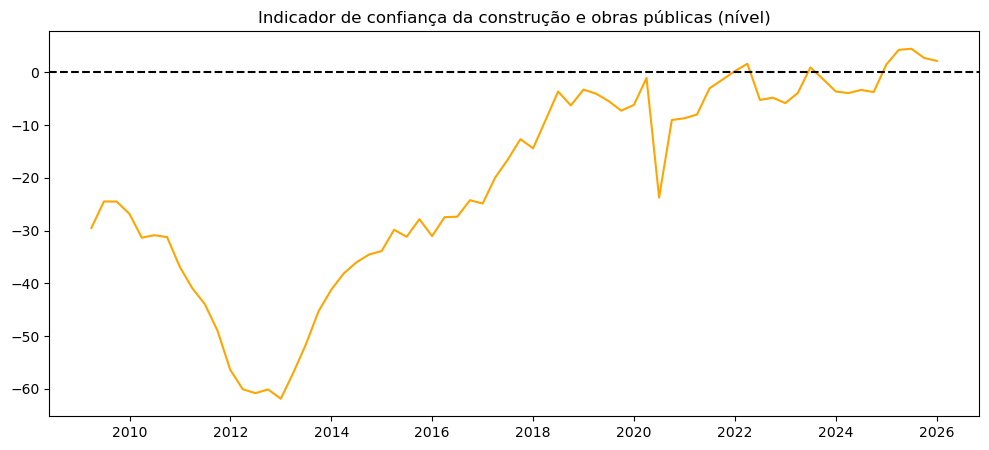


--- ADF ---
Estatística: -0.41530770694055014
p-value: 0.9075113943017579
Valores críticos:
  1%: -3.5335601309235605
  5%: -2.9064436883991434
  10%: -2.590723948576676

--- PP ---
Estatística: -0.8187876850744435
p-value: 0.8135409395300941
Valores críticos:
  1%: -3.5319549603840894
  5%: -2.905755128523123
  10%: -2.5903569458676765

===== 1ª DIFERENÇA =====


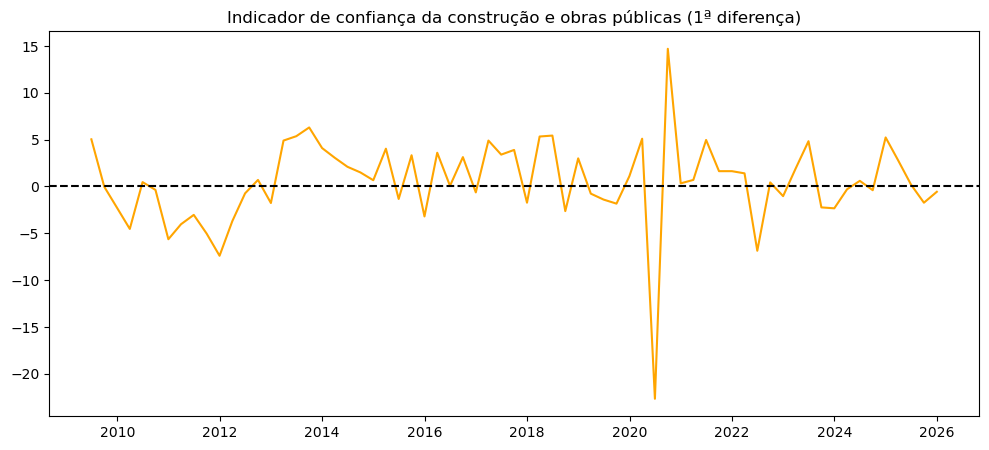


--- ADF ---
Estatística: -9.409477407058015
p-value: 5.888118774781432e-16
Valores críticos:
  1%: -3.5335601309235605
  5%: -2.9064436883991434
  10%: -2.590723948576676

--- PP ---
Estatística: -9.33978841629991
p-value: 8.860499248676175e-16
Valores críticos:
  1%: -3.5335601309235605
  5%: -2.9064436883991434
  10%: -2.590723948576676

================ Perspetivas de atividade nos próximos 3 meses em construção e obras públicas ================


===== NÍVEL =====


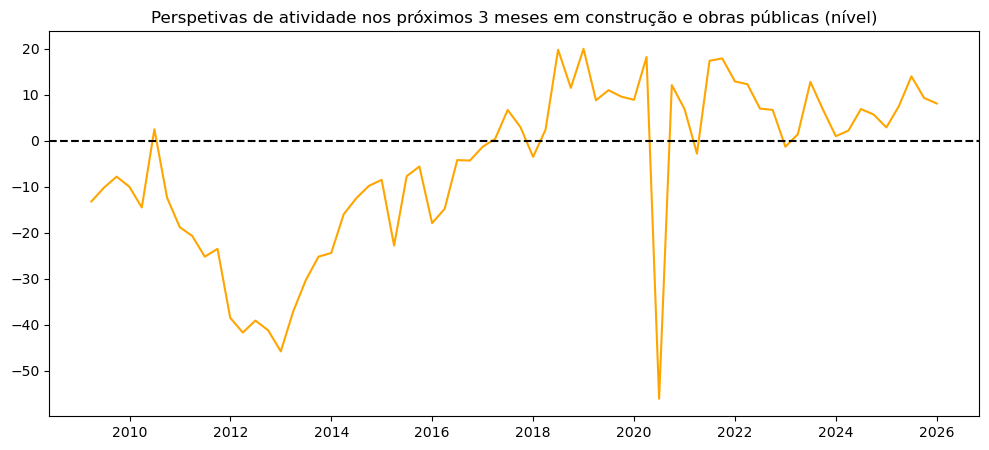


--- ADF ---
Estatística: -1.3113128898390727
p-value: 0.6239808910391946
Valores críticos:
  1%: -3.5352168748293127
  5%: -2.9071540828402367
  10%: -2.5911025443786984

--- PP ---
Estatística: -4.1225910890677415
p-value: 0.0008885187746530183
Valores críticos:
  1%: -3.5319549603840894
  5%: -2.905755128523123
  10%: -2.5903569458676765

===== 1ª DIFERENÇA =====


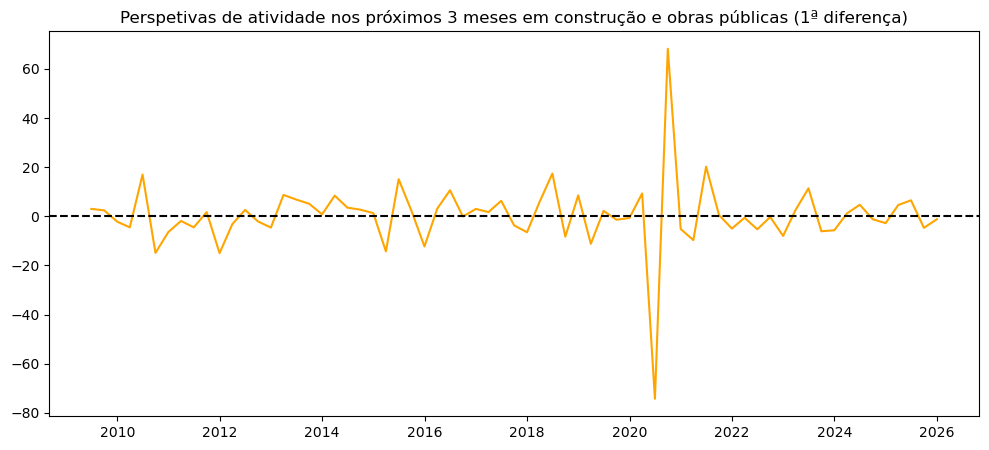


--- ADF ---
Estatística: -9.882176634733511
p-value: 3.744761088731957e-17
Valores críticos:
  1%: -3.5352168748293127
  5%: -2.9071540828402367
  10%: -2.5911025443786984

--- PP ---
Estatística: -18.503308831178707
p-value: 2.119174599786011e-30
Valores críticos:
  1%: -3.5335601309235605
  5%: -2.9064436883991434
  10%: -2.590723948576676

Número de diferenças aplicadas:
{'PIB Real': 1, 'Índice de preços no consumidor (2025=100)': 2, 'Índice de custos de construção de habitação nova (2021=100)': 1, 'Taxa de juro (TAA) de novas operações de empréstimos à habitação (%)': 1, 'População empregada': 1, 'Fogos concluidos em construções novas para habitação': 3, 'Nº de edifícios licenciados': 2, 'Indicador Coincidente para a atividade económica': 2, 'Indicador de confiança da construção e obras públicas': 1, 'Perspetivas de atividade nos próximos 3 meses em construção e obras públicas': 1}


In [11]:
# Guardar resultados
df_exog_estacionarias = pd.DataFrame()
d_exogenas = {}

# Variáveis que serão transformadas em logaritmo
variaveis_log = [
    'PIB Real',
    'Índice de preços no consumidor (2025=100)',
    'Índice de custos de construção de habitação nova (2021=100)',
    'População empregada',
    'Fogos concluidos em construções novas para habitação',
    'Nº de edifícios licenciados'
]

# Variáveis com tendência
variaveis_com_tendencia = [
    'PIB Real',
    'Índice de preços no consumidor (2025=100)',
    'Índice de custos de construção de habitação nova (2021=100)',
    'População empregada'
]

def plot_serie(serie, titulo):
    plt.figure(figsize=(12,5))
    plt.plot(serie, color='orange')
    plt.axhline(y=0, color='black', linestyle='--')
    plt.title(titulo)
    plt.show()

def testa_estacionaridade(serie, tipo_reg):

    adf_res = adfuller(serie.dropna(), regression=tipo_reg)
    pp_res = PhillipsPerron(serie.dropna(), trend=tipo_reg)

    print("\n--- ADF ---")
    print("Estatística:", adf_res[0])
    print("p-value:", adf_res[1])
    print("Valores críticos:")
    for k, v in adf_res[4].items():
        print(f"  {k}: {v}")

    print("\n--- PP ---")
    print("Estatística:", pp_res.stat)
    print("p-value:", pp_res.pvalue)

    print("Valores críticos:")
    try:
        for k, v in pp_res.critical_values.items():
            print(f"  {k}: {v}")
    except:
        print("  (Valores críticos não disponíveis nesta versão do PP)")

    return adf_res, pp_res


for col in exog.columns:

    print(f"\n================ {col} ================\n")

    serie = exog[col].copy()

    # Aplicar logaritmo apenas às variáveis adequadas
    if col in variaveis_log:

        if (serie <= 0).any():
            print(f"A variável {col} contém valores menores ou iguais a zero. Não foi possível aplicar logaritmo.")
        else:
            serie = np.log(serie)

    # definição do modelo determinístico no nível
    if col in variaveis_com_tendencia:
        reg_inicial = 'ct'
    else:
        reg_inicial = 'c'

    # =====================
    # NÍVEL
    # =====================
    d = 0
    serie_est = serie.copy()

    while True:

        if d == 0:
            print("\n===== NÍVEL =====")
            plot_serie(serie_est, f"{col} (nível)")
        else:
            print(f"\n===== {d}ª DIFERENÇA =====")
            plot_serie(
                serie_est.dropna(),
                f"{col} ({d}ª diferença)"
            )

        adf_res, pp_res = testa_estacionaridade(
            serie_est,
            reg_inicial
        )

        # Se ambos os testes indicarem estacionariedade, termina
        if adf_res[1] <= 0.05 and pp_res.pvalue <= 0.05:
            break

        # Caso contrário, diferencia novamente
        serie_est = serie_est.diff()
        d += 1

        # Segurança: impedir diferenciações infinitas
        if d == 5:
            print(f"\nA variável {col} continua não estacionária após 5 diferenciações.")
            break

    df_exog_estacionarias[col] = serie_est
    d_exogenas[col] = d

df_exog_estacionarias = df_exog_estacionarias.reindex(
    y_estacionaria.index
)

print("\nNúmero de diferenças aplicadas:")
print(d_exogenas)

# Testar a significância 

In [12]:
# Copiar a variável endógena
y = y_estacionaria.copy()
x = df_exog_estacionarias.copy().dropna()

# Reindexar y para ter o mesmo índice que x
y = y.reindex(x.index)

#Adicionar constante para OLS
x=sm.add_constant(x)

#Testar a significância
modelo_ols=sm.OLS(y,x).fit()
print(modelo_ols.summary())

                            OLS Regression Results                            
Dep. Variable:       Índice de Preços   R-squared:                       0.527
Model:                            OLS   Adj. R-squared:                  0.439
Method:                 Least Squares   F-statistic:                     6.015
Date:                Wed, 16 Sep 2026   Prob (F-statistic):           4.62e-06
Time:                        14:14:38   Log-Likelihood:                 191.18
No. Observations:                  65   AIC:                            -360.4
Df Residuals:                      54   BIC:                            -336.4
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                                                                   coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

In [13]:
##Eliminar variáveis com um p-value >0.05
# Obter os p-values do modelo
pvalues = modelo_ols.pvalues

# Remover a constante
pvalues = pvalues.drop("const")

# Selecionar as variáveis significativas
variaveis_significativas = pvalues[pvalues <= 0.05].index

print("Variáveis significativas:")
print(variaveis_significativas)

# Criar um novo dataframe apenas com essas variáveis
df_exog_selecionadas = df_exog_estacionarias[variaveis_significativas]

Variáveis significativas:
Index(['PIB Real',
       'Índice de custos de construção de habitação nova (2021=100)',
       'População empregada'],
      dtype='object')


# Multicolinearidade

In [14]:
def calcular_vif(df):
    x = sm.add_constant(df)
    vif = pd.DataFrame()
    vif["Variavel"] = x.columns
    vif["VIF"] = [variance_inflation_factor(x.values, i) for i in range(x.shape[1])]
    return vif

In [15]:
while True:
    vif = calcular_vif(df_exog_selecionadas)
    
    # remover constante
    vif_sem_const = vif[vif["Variavel"] != "const"]
    
    max_vif = vif_sem_const["VIF"].max()
    
    if max_vif > 5:
        var_remover = vif_sem_const.sort_values("VIF", ascending=False)["Variavel"].iloc[0]
        print("Remover:", var_remover)
        
        df_exog_selecionadas = df_exog_selecionadas.drop(columns=[var_remover])
        
    else:
        break

print("\nVariáveis finais:")
print(df_exog_selecionadas.columns)

print("\nVIF final:")
print(calcular_vif(df_exog_selecionadas))


Variáveis finais:
Index(['PIB Real',
       'Índice de custos de construção de habitação nova (2021=100)',
       'População empregada'],
      dtype='object')

VIF final:
                                            Variavel       VIF
0                                              const  1.609232
1                                           PIB Real  1.532044
2  Índice de custos de construção de habitação no...  1.177652
3                                População empregada  1.446415


# Amostra de treino e de teste das variáveis exógenas

In [16]:
#Amostra de treino e de teste da série estacionária
x_treino_est=df_exog_selecionadas.iloc[:-20].asfreq('QE')
x_teste_est=df_exog_estacionarias.iloc[-20:].asfreq('QE')

y_treino_log_2=y_treino_log.copy()
y_treino_log_2=y_treino_log_2.reindex(x_treino_est.index)

# Concatenar y e x para garantir alinhamento
df_temp=y_treino_log_2.join(x_treino_est, how="inner").dropna() #juntar todos os dados num só dataframe

# Separar novamente
y_treino_log_alinhado = df_temp.iloc[:, 0]  
x_treino_est_alinhado = df_temp.iloc[:, 1:]

# ARIMAX

In [17]:
# Todas as combinações de 1 até N variáveis exógenas
lista_combinacoes_x = []
for r in range(1, len(x_treino_est_alinhado.columns)+1):
    lista_combinacoes_x.extend(combinations(x_treino_est_alinhado.columns, r))


resultados_arimax = []
previsoes_modelos_arimax = {}

p=range(0,5)
d=[1]
q=range(0,5)


parametros_arimax = list(product(p,d,q))

for param in parametros_arimax:
    for comb in lista_combinacoes_x:
        x_comb = x_treino_est_alinhado[list(comb)].copy()

        # Garantir alinhamento com y
        x_comb = x_comb.loc[y_treino_log_alinhado.index]
        try:
            #Arimax
            x_final = x_comb.join(x_treino_dummy, how="inner")
            x_final = x_final.loc[y_treino_log_alinhado.index]
            x_final = x_final.reindex(y_treino_log_alinhado.index)
            modelo_arimax = ARIMA(y_treino_log_alinhado, order=param, exog=x_final, trend='t').fit()
            convergiu= modelo_arimax.mle_retvals.get("converged", False)
            if not convergiu:
                continue
            else:
                print(modelo_arimax.summary())
            
        except:
            continue
            
        x_teste_comb = x_teste_est[list(comb)].copy() #Criar a amostra de teste das combinações de variaveis
        x_teste_final = x_teste_comb.join(dummys_teste_crises, how="inner")
        
        # Previsão na amostra de teste
        previsao_log = modelo_arimax.forecast(steps=len(y_teste_log),exog=x_teste_final)
        previsao = np.exp(previsao_log)
        
        # Métricas
        eqm_arimax = mean_squared_error(np.exp(y_teste_log), previsao)
        epam_arimax = mean_absolute_percentage_error(np.exp(y_teste_log), previsao)
        aic_arimax = modelo_arimax.aic
        
        # Guardar resultados
        resultados_arimax.append({
            "p": param[0],
            "d": param[1],
            "q": param[2],
            "Exog": comb,
            "AIC": aic_arimax,
            "EQM": eqm_arimax,
            "EPAM": epam_arimax,
        })
        
        previsoes_modelos_arimax[(param, comb)] = previsao
        
df_resultados_arimax = pd.DataFrame(resultados_arimax)
df_resultados_arimax = df_resultados_arimax.sort_values(by="AIC").reset_index(drop=True)

top5_arimax = df_resultados_arimax.head(5)
print("Top 5 ARIMAX:")
print(top5_arimax)

df_previsoes_arimax = pd.DataFrame(index=y_teste_log.index)

parametros_linhas = []
for i, row in top5_arimax.iterrows():
    key = ((row['p'], row['d'], row['q']), row['Exog'])
    df_previsoes_arimax[f"ARIMAX{key}"] = previsoes_modelos_arimax[key].values
    parametros_linhas.append(str(key))

# Adicionar coluna Real
df_previsoes_arimax["Real"] = np.exp(y_teste_log.values)
parametros_linhas.append("Real")

# Criar DataFrame final com primeira linha como parâmetros
df_final = pd.DataFrame(columns=df_previsoes_arimax.columns)
df_final.loc[0] = parametros_linhas
df_final = pd.concat([df_final, df_previsoes_arimax], ignore_index=True)

# Guardar em Excel
df_final.to_excel("Resultados_ARIMAX.xlsx", sheet_name="Previsoes_Teste", index=True)

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:       Índice de Preços   No. Observations:                   47
Model:                 ARIMA(0, 1, 0)   Log Likelihood                 120.752
Date:                Wed, 16 Sep 2026   AIC                           -233.504
Time:                        14:14:43   BIC                           -226.190
Sample:                    06-30-2009   HQIC                          -230.764
                         - 12-31-2020                                         
Covariance Type:                  opg                                         
                                                                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------------
drift                                                           0.0085      0.003      3.193      0.001       0.

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:       Índice de Preços   No. Observations:                   47
Model:                 ARIMA(0, 1, 2)   Log Likelihood                 131.846
Date:                Wed, 16 Sep 2026   AIC                           -251.692
Time:                        14:14:43   BIC                           -240.720
Sample:                    06-30-2009   HQIC                          -247.582
                         - 12-31-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
drift          0.0086      0.004      2.024      0.043       0.000       0.017
PIB Real      -0.0704      0.046     -1.530      0.126      -0.161       0.020
crises        -0.0049      0.013     -0.384      0.7

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:       Índice de Preços   No. Observations:                   47
Model:                 ARIMA(0, 1, 2)   Log Likelihood                 129.687
Date:                Wed, 16 Sep 2026   AIC                           -245.374
Time:                        14:14:44   BIC                           -232.574
Sample:                    06-30-2009   HQIC                          -240.579
                         - 12-31-2020                                         
Covariance Type:                  opg                                         
                                                                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------------
drift                                                           0.0088      0.004      2.018      0.044       0.

... (39 outputs left out)

                               SARIMAX Results                                
Dep. Variable:       Índice de Preços   No. Observations:                   47
Model:                 ARIMA(4, 1, 3)   Log Likelihood                 140.688
Date:                Wed, 16 Sep 2026   AIC                           -255.376
Time:                        14:14:59   BIC                           -231.604
Sample:                    06-30-2009   HQIC                          -246.471
                         - 12-31-2020                                         
Covariance Type:                  opg                                         
                                                                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------------
drift                                                           0.0086      0.011      0.779      0.436      -0.

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:       Índice de Preços   No. Observations:                   47
Model:                 ARIMA(4, 1, 4)   Log Likelihood                 140.418
Date:                Wed, 16 Sep 2026   AIC                           -254.837
Time:                        14:15:00   BIC                           -231.065
Sample:                    06-30-2009   HQIC                          -245.932
                         - 12-31-2020                                         
Covariance Type:                  opg                                         
                                                                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------------
drift                                                           0.0090      0.010      0.907      0.365      -0.

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


# Teste de cointegração

In [24]:
#Separar os dados em amostra de treino e de teste
dados_vecm = dados_completos[["Índice de Preços"] + list(df_exog_selecionadas.columns)].dropna()
# Aplicar o logaritmo natural em todas as colunas
dados_vecm_log = np.log(dados_vecm)

dummys_vecm=pd.DataFrame(index=log_habitacional.index)
dummys_vecm["crises"]=(((dummys.index <= "2014-12-31") & (dummys.index >= "2009-03-31"))).astype(int) 

dados_vecm_treino=dados_vecm_log.iloc[:-20].asfreq('QE')
dados_vecm_teste=dados_vecm_log.iloc[-20:].asfreq('QE')

dummys_vecm_treino=dummys_vecm["crises"].iloc[:-20].asfreq('QE')
dummys_vecm_treino = dummys_vecm_treino.to_frame()
dummys_vecm_teste=dummys_vecm["crises"].iloc[-20:].asfreq('QE')
dummys_vecm_teste = dummys_vecm_teste.to_frame()

#Definfir o número de lags que minimiza o AIC, BIC, HQIC e FPE
ordem_treino = select_order(dados_vecm_treino, exog= dummys_vecm_treino, maxlags=4,deterministic="cilo")
print(ordem_treino.summary())

 VECM Order Selection (* highlights the minimums)
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -37.98     -36.67*   3.255e-17      -37.50
1     -38.41*      -36.45  2.211e-17*     -37.69*
2      -37.93      -35.31   3.916e-17      -36.96
3      -37.82      -34.55   5.099e-17      -36.62
4      -37.61      -33.68   8.234e-17      -36.16
-------------------------------------------------


In [25]:
#Teste de Johansen
johansen = select_coint_rank(
    dados_vecm_treino,
    det_order=0, #linear trend
    k_ar_diff=ordem_treino.aic,
    method='trace',
    signif=0.05
)

print(johansen.summary())

#Teste de Johansen
johansen = select_coint_rank(
    dados_vecm_treino,
    det_order=0, #linear trend
    k_ar_diff=ordem_treino.bic,
    method='trace',
    signif=0.05
)

print(johansen.summary())


Johansen cointegration test using trace test statistic with 5% significance level
r_0 r_1 test statistic critical value
-------------------------------------
  0   4          48.26          47.85
  1   4          26.99          29.80
-------------------------------------
Johansen cointegration test using trace test statistic with 5% significance level
r_0 r_1 test statistic critical value
-------------------------------------
  0   4          74.36          47.85
  1   4          42.71          29.80
  2   4          14.55          15.49
-------------------------------------


# Modelo de Vetores de Correção de Erros

In [27]:
#Estimar o VECM com diferentes especificações
k_ar_options = {"AIC": ordem_treino.aic, "BIC": ordem_treino.bic}
coint_ranks = [1,2]
resultados = []
previsoes_vecm = {}
modelos_vecm = {}

for k_name, k_val in k_ar_options.items():
    for r in coint_ranks:
        print(f"Estimando VECM | k_ar_diff={k_name} ({k_val}) | rank={r}")

        try:
            # Estimar modelo
            modelo = VECM(dados_vecm_treino,exog=dummys_vecm_treino, k_ar_diff=k_val,coint_rank=r, deterministic="cilo")
            resultado = modelo.fit()
            nome = f"VECM_{k_val}_r{r}"
            modelos_vecm[nome] = resultado
            
            #Previsão
            pred = resultado.predict(steps=len(dados_vecm_teste),exog_fc=dummys_vecm_teste)
            previsao_log = pd.DataFrame(pred,index=dados_vecm_teste.index,columns=dados_vecm_treino.columns)
            previsao = np.exp(previsao_log)
            
            # EQM e EPAM apenas para Índice de Preços
            y_real = np.exp(dados_vecm_teste["Índice de Preços"])
            y_pred = previsao["Índice de Preços"]
            eqm = mean_squared_error(y_real, y_pred)
            epam = mean_absolute_percentage_error(y_real, y_pred)
            resultados.append({"k_ar_diff": int(k_val),"coint_rank": int(r),"EQM": eqm,"EPAM": epam})
            
            #Guardar previsões
            nome = f"VECM_{int(k_val)}_r{int(r)}"
            previsoes_vecm[nome] = previsao
            print(resultado.summary())
            
        except Exception as e:
            print(f"Erro no modelo k={k_name}, rank={r}: {e}")


df_resultados = pd.DataFrame(resultados)
print(df_resultados)

with pd.ExcelWriter("Resultados_VECM_.xlsx") as writer:

    # tabela de métricas
    df_resultados.to_excel(writer, sheet_name="Metricas", index=False)

    # previsões
    for nome, df in previsoes_vecm.items():
        df.to_excel(writer, sheet_name=nome[:31])

Estimando VECM | k_ar_diff=AIC (1) | rank=1
                 Det. terms outside the coint. relation & lagged endog. parameters for equation Índice de Preços                  
                                                                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------------
lin_trend                                                          0.0032      0.002      2.015      0.044    8.86e-05       0.006
exog1                                                             -0.0126      0.004     -3.187      0.001      -0.020      -0.005
L1.Índice de Preços                                               -0.0422      0.167     -0.253      0.800      -0.370       0.285
L1.PIB Real                                                       -0.0234      0.100     -0.234      0.815      -0.219       0.173
L1.Índice de custos de construção de ha

In [28]:
melhor_modelo_vecm = df_resultados.sort_values("EQM").iloc[0]

k = int(round(melhor_modelo_vecm["k_ar_diff"]))
r = int(round(melhor_modelo_vecm["coint_rank"]))

print("Melhor modelo encontrado:")
print(melhor_modelo_vecm)

# chave do melhor modelo
best_key = f"VECM_{int(melhor_modelo_vecm['k_ar_diff'])}_r{int(melhor_modelo_vecm['coint_rank'])}"
melhor_previsao_vecm = previsoes_vecm[best_key]
melhor_vecm = modelos_vecm[best_key]

print(melhor_vecm.summary())

Melhor modelo encontrado:
k_ar_diff      0.000000
coint_rank     2.000000
EQM           23.266018
EPAM           0.017878
Name: 3, dtype: float64
Det. terms outside the coint. relation & lagged endog. parameters for equation Índice de Preços
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
lin_trend      0.0038      0.002      2.443      0.015       0.001       0.007
exog1         -0.0127      0.003     -4.362      0.000      -0.018      -0.007
Det. terms outside the coint. relation & lagged endog. parameters for equation PIB Real
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
lin_trend      0.0073      0.003      2.157      0.031       0.001       0.014
exog1          0.0096      0.006      1.494      0.135      -0.003       0.022
Det. terms outside the coint. relation

# Método de Holt

In [29]:
modelo_holt=Holt(y_treino).fit() #Ajustar o modelo de Holt

previsao_holt = modelo_holt.forecast(steps=len(y_teste)) #Fazer a previsão para o mesmo período da amostra de teste

eqm_holt = mean_squared_error(y_teste, previsao_holt)
epam_holt = mean_absolute_percentage_error(y_teste, previsao_holt)
aic_holt = modelo_holt.aic

print(modelo_holt.summary())
print("EQM:", eqm_holt)
print("EPAM:", epam_holt)
print("AIC:", aic_holt)

df_holt = pd.DataFrame({"Real": y_teste.values.ravel(),"Holt": previsao_holt.values.ravel()}, index=y_teste.index)

df_holt.to_excel("Resultados_Holt.xlsx")

                              Holt Model Results                              
Dep. Variable:       Índice de Preços   No. Observations:                   48
Model:                           Holt   SSE                            103.746
Optimized:                       True   AIC                             44.996
Trend:                       Additive   BIC                             52.480
Seasonal:                        None   AICC                            47.044
Seasonal Periods:                None   Date:                 Wed, 16 Sep 2026
Box-Cox:                        False   Time:                         14:17:01
Box-Cox Coeff.:                  None                                         
                       coeff                 code              optimized      
------------------------------------------------------------------------------
smoothing_level            0.8996286                alpha                 True
smoothing_trend            0.3792392                

# Previsão (ARIMA vs ARIMAX vs VECM vs Holt)

In [30]:
# Escolher o melhor modelo de cada tipo
melhor_arima = top5_arimas.sort_values("EQM").iloc[0]
melhor_arimax = top5_arimax.sort_values("EQM").iloc[0]
melhor_holt = {
    "EQM": eqm_holt,
    "EPAM": epam_holt,
    "AIC": aic_holt,
    "Modelo": "Holt"
}

# Juntar os melhores modelos
resultados = {

    "ARIMA": {
        "EQM": melhor_arima["EQM"],
        "EPAM": melhor_arima["EPAM"],
        "p": melhor_arima["p"],
        "d": melhor_arima["d"],
        "q": melhor_arima["q"]
    },

    "ARIMAX": {
        "EQM": melhor_arimax["EQM"],
        "EPAM": melhor_arimax["EPAM"],
        "p": melhor_arimax["p"],
        "d": melhor_arimax["d"],
        "q": melhor_arimax["q"],
        "Exog": melhor_arimax["Exog"]
    },

    "Holt": {
        "EQM": melhor_holt["EQM"],
        "EPAM": melhor_holt["EPAM"],
        "AIC": melhor_holt["AIC"],
    },

    "VECM": {
        "EQM": melhor_modelo_vecm["EQM"],
        "EPAM": melhor_modelo_vecm["EPAM"],
        "k_ar_diff": int(melhor_modelo_vecm["k_ar_diff"]),
        "coint_rank": int(melhor_modelo_vecm["coint_rank"])
    }

}

print(resultados)

{'ARIMA': {'EQM': np.float64(706.6532799308094), 'EPAM': np.float64(0.09195063665490769), 'p': np.float64(2.0), 'd': np.float64(1.0), 'q': np.float64(1.0)}, 'ARIMAX': {'EQM': np.float64(1012.0319736599356), 'EPAM': np.float64(0.10821876193054361), 'p': np.int64(4), 'd': np.int64(1), 'q': np.int64(0), 'Exog': ('PIB Real', 'Índice de custos de construção de habitação nova (2021=100)')}, 'Holt': {'EQM': 1025.0549568880147, 'EPAM': 0.11263886366145763, 'AIC': np.float64(44.99559281205435)}, 'VECM': {'EQM': np.float64(23.266018420083377), 'EPAM': np.float64(0.01787825236772907), 'k_ar_diff': 0, 'coint_rank': 2}}


In [31]:
#Dos três escolher qual é o modelo que minimiza o EPAM e EQM
melhor_modelo = min(
    resultados,
    key=lambda m: (
        resultados[m]["EQM"],
        resultados[m]["EPAM"]
    )
)

print("Melhor modelo:", melhor_modelo)

Melhor modelo: VECM


Det. terms outside the coint. relation & lagged endog. parameters for equation Índice de Preços
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
lin_trend      0.0006   6.62e-05      9.220      0.000       0.000       0.001
exog1         -0.0121      0.003     -3.984      0.000      -0.018      -0.006
Det. terms outside the coint. relation & lagged endog. parameters for equation PIB Real
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
lin_trend     -0.0005      0.000     -3.508      0.000      -0.001      -0.000
exog1          0.0113      0.006      1.885      0.059      -0.000       0.023
Det. terms outside the coint. relation & lagged endog. parameters for equation Índice de custos de construção de habitação nova (2021=100)
                 coef    std err          z  

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QE-DEC will be used.
  self._init_dates(dates, freq)
/var/folders/z0/1s25mqbs13565qd8bkwst_kh0000gn/T/ipykernel_58910/1128515241.py:68: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  futuro_index = pd.date_range(start=dados_vecm_log.index[-1],periods=h + 1,freq="Q")[1:]
/var/folders/z0/1s25mqbs13565qd8bkwst_kh0000gn/T/ipykernel_58910/1128515241.py:79: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  datas_futuras = pd.date_range(start=ultimo,periods=h+1,freq="Q")[1:]


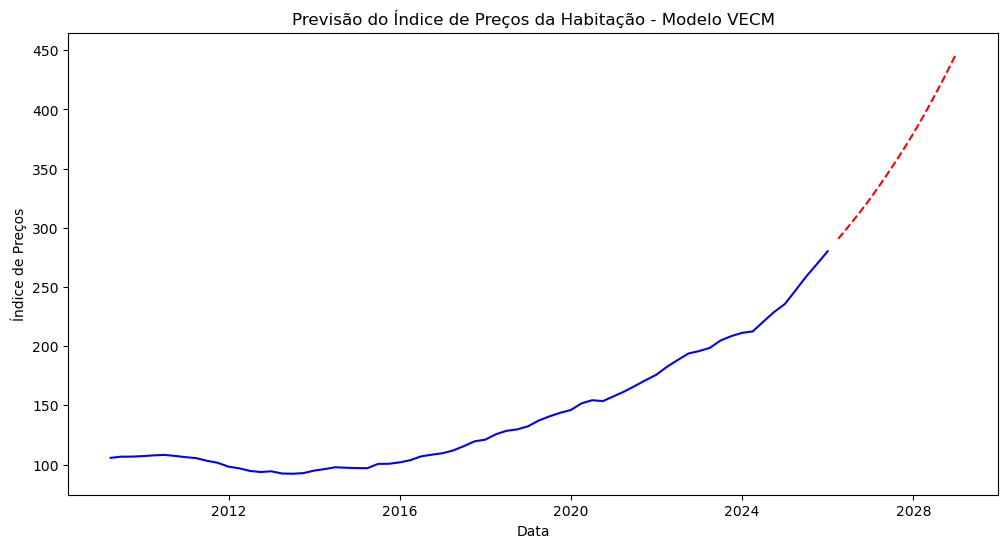


Tabela de Previsões
         Data  Previsão (VECM)       TVT        TVH
0  2026-03-31       290.698241  3.742993  17.667776
1  2026-06-30       301.551048  3.733358  16.527957
2  2026-09-30       312.935657  3.775350  16.181792
3  2026-12-31       324.911690  3.826995  15.952925
4  2027-03-31       337.519784  3.880468  16.106580
5  2027-06-30       350.798852  3.934308  16.331498
6  2027-09-30       364.789564  3.988243  16.570150
7  2027-12-31       379.535170  4.042223  16.811793
8  2028-03-31       395.081827  4.096236  17.054420
9  2028-06-30       411.478837  4.150282  17.297658
10 2028-09-30       428.778888  4.204360  17.541435
11 2028-12-31       447.038304  4.258469  17.785739


In [32]:
##Previsão h-passos à frente 
# Horizonte de previsão
h = 12

if melhor_modelo == "ARIMA":
    ordem = (int(resultados["ARIMA"]["p"]),int(resultados["ARIMA"]["d"]),int(resultados["ARIMA"]["q"]))
    futuro_index = pd.date_range(start=log_habitacional.index[-1],periods=h+1,freq='Q')[1:]
    dummys_futuro = pd.DataFrame(0, index=range(h), columns=['crises']) 
    dummys_futuro = dummys_futuro.set_index(futuro_index)
    serie_completa=log_habitacional.join(dummys,how="inner").dropna()
    y_completo=serie_completa.iloc[:,0]
    x_completo=serie_completa.iloc[:,1:]
    modelo_final = ARIMA(y_completo,order=ordem, exog=x_completo, trend='t').fit() #criar o modelo com a série completa
    print(modelo_final.summary())
    previsao_log = modelo_final.forecast(steps=h, exog=dummys_futuro) #previsão com o log
    previsao = np.exp(previsao_log) #tirar o log
    
elif melhor_modelo == "ARIMAX":
    ordem = (int(resultados["ARIMAX"]["p"]),int(resultados["ARIMAX"]["d"]),int(resultados["ARIMAX"]["q"]))
    exog_vars = list(resultados["ARIMAX"]["Exog"])
    x_completo = df_exog_estacionarias[exog_vars]
    x_completo = x_completo.join(dummys["crises"], how="inner")
    df_temp = log_habitacional.join(x_completo, how="inner").dropna() #alinhar índices   
    y_completo = df_temp.iloc[:, 0]
    x_completo = df_temp.iloc[:, 1:]
    modelo_final = ARIMA(y_completo,order=ordem,exog=x_completo, trend='t').fit() #criar as séries completas
    print(modelo_final.summary())

    variaveis_reais = x_completo.iloc[:,:-1]
    variaveis_dummy = x_completo.iloc[:,-1:]
    
    #Prever o futuro das variáveis exógenas
    previsoes_exog={}
    for col in variaveis_reais.columns:
        #modelo_exog = ExponentialSmoothing(x_completo[col], trend='add').fit() 
        modelo_exog=Holt(x_completo[col]).fit()
        previsoes_exog[col] = modelo_exog.forecast(steps=h)
    
    futuro_index = pd.date_range(start=y_completo.index[-1],periods=h+1,freq='Q')[1:]
    dummys_futuro = pd.DataFrame(0, index=range(h), columns=['crises']) 
    dummys_futuro = dummys_futuro.set_index(futuro_index)
    x_futuro = pd.concat(previsoes_exog.values(), axis=1)
    x_futuro_final = pd.concat([x_futuro, dummys_futuro], axis=1)
    x_futuro.to_excel("previsoes_variaveis_exogenas.xlsx") #guardar a previsão das variáveis exógenas no excel
    previsao_log = modelo_final.forecast(steps=h,exog=x_futuro_final) #previsão em log
    previsao = np.exp(previsao_log) #tirar o log

elif melhor_modelo == "Holt":
    y_completo = habitacional.copy()
    # Ajustar modelo de Holt
    modelo_final = Holt(y_completo).fit()
    print(modelo_final.summary())

    # Previsão h-passos à frente
    previsao = modelo_final.forecast(steps=h)
    
elif melhor_modelo == "VECM":
    # Obter parâmetros do melhor modelo
    k = int(resultados["VECM"]["k_ar_diff"])
    r = int(resultados["VECM"]["coint_rank"])

    # Estimar o modelo com a amostra completa
    modelo_final = VECM(dados_vecm_log,exog=dummys_vecm['crises'], k_ar_diff=k, coint_rank=r, deterministic="cilo")
    resultado_final = modelo_final.fit()
    print(resultado_final.summary())

    # Previsão
    futuro_index = pd.date_range(start=dados_vecm_log.index[-1],periods=h + 1,freq="Q")[1:]
    dummys_futuro = pd.DataFrame(0, index=futuro_index, columns=dummys_vecm.columns)
    previsoes_log = resultado_final.predict(steps=h,exog_fc=dummys_futuro)
    previsoes= np.exp(previsoes_log)
    previsao_vecm = pd.DataFrame(previsoes,index=futuro_index,columns=dados_vecm.columns)

    # Apenas o Índice de Preços
    previsao = previsao_vecm["Índice de Preços"]

    
ultimo = habitacional.index[-1]
datas_futuras = pd.date_range(start=ultimo,periods=h+1,freq="Q")[1:]
previsao.index = datas_futuras

#Criar o gráfico
plt.figure(figsize=(12,6))
plt.plot(habitacional.index, habitacional['Índice de Preços'], label="Série Original", color="blue")
plt.plot(previsao.index, previsao, label=f"Previsão {melhor_modelo}", color="red", linestyle="--")
plt.title(f"Previsão do Índice de Preços da Habitação - Modelo {melhor_modelo}")
plt.xlabel("Data")
plt.ylabel("Índice de Preços")
plt.show()

serie_completa=pd.concat([habitacional['Índice de Preços'],previsao])
serie_completa_tvt=serie_completa.pct_change(1)*100 #Calcular a taxa de variação trimestral
serie_completa_tvh=serie_completa.pct_change(4)*100 #Calcular a taxa de variação homóloga

previsoes_futuras=pd.DataFrame({"Data":previsao.index,f"Previsão ({melhor_modelo})": previsao.values,"TVT":serie_completa_tvt[-len(previsao):].values,"TVH":serie_completa_tvh[-len(previsao):].values})

print("\nTabela de Previsões")
print(previsoes_futuras)

#Criar um ficheiro Excel com os resultados
serie_completa_df=serie_completa.to_frame(name='Índice de Preços').reset_index()
serie_completa_df=serie_completa_df.rename(columns={'index': 'Data'})

wb= Workbook()
ws=wb.active
ws.title="Previsão Imobiliário"

for r in dataframe_to_rows(serie_completa_df, index=False, header=True):
    ws.append(r)

wb.save("Serie_Completa_Prev.xlsx")

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QE-DEC will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QE-DEC will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QE-DEC will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QE-DEC will be used.
  self._init_dates(dates, freq)


Det. terms outside the coint. relation & lagged endog. parameters for equation Índice de Preços
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
lin_trend      0.0006   6.62e-05      9.220      0.000       0.000       0.001
exog1         -0.0121      0.003     -3.984      0.000      -0.018      -0.006
Det. terms outside the coint. relation & lagged endog. parameters for equation PIB Real
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
lin_trend     -0.0005      0.000     -3.508      0.000      -0.001      -0.000
exog1          0.0113      0.006      1.885      0.059      -0.000       0.023
Det. terms outside the coint. relation & lagged endog. parameters for equation Índice de custos de construção de habitação nova (2021=100)
                 coef    std err          z  

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QE-DEC will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QE-DEC will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QE-DEC will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QE-DEC will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequenc

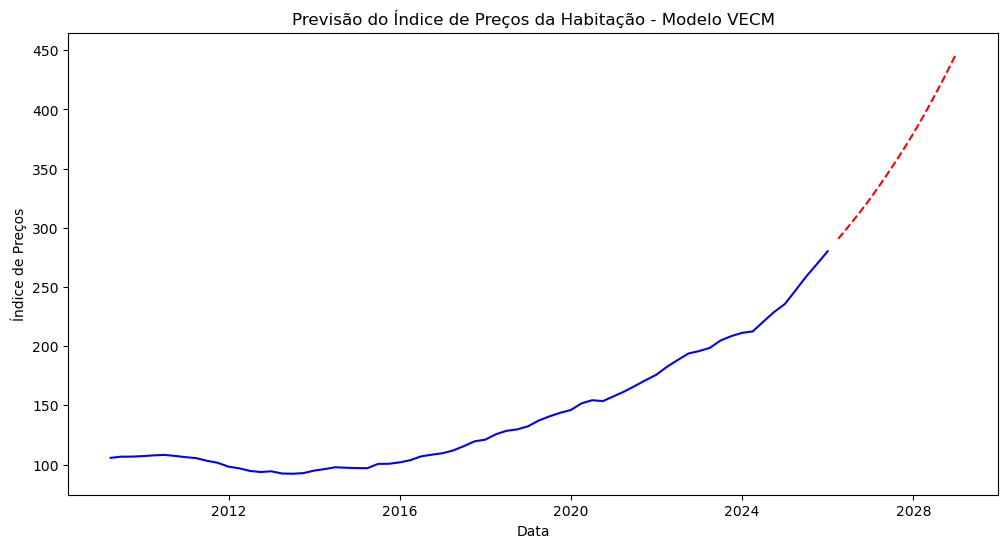


Tabela de Previsões
         Data  Previsão (VECM)       TVT        TVH
0  2026-03-31       290.698241  3.742993  17.667776
1  2026-06-30       301.551048  3.733358  16.527957
2  2026-09-30       312.935657  3.775350  16.181792
3  2026-12-31       324.911690  3.826995  15.952925
4  2027-03-31       337.519784  3.880468  16.106580
5  2027-06-30       350.798852  3.934308  16.331498
6  2027-09-30       364.789564  3.988243  16.570150
7  2027-12-31       379.535170  4.042223  16.811793
8  2028-03-31       395.081827  4.096236  17.054420
9  2028-06-30       411.478837  4.150282  17.297658
10 2028-09-30       428.778888  4.204360  17.541435
11 2028-12-31       447.038304  4.258469  17.785739


In [33]:
##Previsão passo a passo
# Horizonte de previsão
h = 12
    
if melhor_modelo == "ARIMA":
    x_completo = dummys['crises'].copy()
    df_temp = log_habitacional.join(x_completo, how="inner").dropna() #alinhas índices   
    y_alinhado = df_temp.iloc[:, 0]
    x_alinhado = df_temp.iloc[:, 1:]   
    futuro_index = pd.date_range(start=y_alinhado.index[-1],periods=h+1,freq='QE')[1:]
    dummys_futuro = pd.DataFrame(0, index=range(h), columns=['crises']) 
    dummys_futuro = dummys_futuro.set_index(futuro_index)    

    previsoes = []
    historico_y=y_alinhado.copy()
    historico_x=x_alinhado.copy()

    for t in range(h):
        modelo_temp= ARIMA(historico_y,order=ordem,exog=historico_x, trend='t').fit()
        print(modelo_temp.summary())
        exog_t = dummys_futuro.iloc[[t]]
        pred = modelo_temp.forecast(steps=1, exog=exog_t)
        pred = pd.Series(pred.iloc[0], index=[futuro_index[t]])
        previsoes.append(pred.iloc[0])        
        historico_y = pd.concat([historico_y, pred])
        historico_x = pd.concat([historico_x, exog_t])
    
    previsao_final = pd.Series(previsoes, index=futuro_index)
    previsao = np.exp(previsao_final) #tirar o log
    
elif melhor_modelo == "ARIMAX":
    futuro_index = pd.date_range(start=y_completo.index[-1],periods=h+1,freq='QE')[1:]
    dummys_futuro = pd.DataFrame(0, index=range(h), columns=['crises']) 
    dummys_futuro = dummys_futuro.set_index(futuro_index)
    x_futuro = pd.concat(previsoes_exog.values(), axis=1)
    x_futuro.index=futuro_index
    x_futuro_final = pd.concat([x_futuro, dummys_futuro], axis=1)
    x_futuro_final.columns = list(exog_vars) + ["crises"]
    modelo_final = ARIMA(y_completo, order=ordem, exog=x_completo, trend='t').fit()

    previsoes = []
    historico_y=y_completo.copy()
    historico_x=x_completo.copy()

    for t in range(h):
        modelo_temp= ARIMA(historico_y,order=ordem,exog=historico_x, trend='t').fit()
        print(modelo_temp.summary())
        exog_t = x_futuro_final.iloc[[t]]
        pred = modelo_temp.forecast(steps=1, exog=exog_t)
        pred = pd.Series(pred.iloc[0], index=[futuro_index[t]])
        previsoes.append(pred.iloc[0])
        
        historico_y = pd.concat([historico_y, pred])
        historico_x = pd.concat([historico_x, exog_t])
    
    previsao_final = pd.Series(previsoes, index=futuro_index)
    previsao = np.exp(previsao_final) #tirar o log
    
elif melhor_modelo == "Holt":

    # Série completa (em log)
    y_completo = log_habitacional.iloc[:, 0].copy()
    
    futuro_index = pd.date_range(start=y_completo.index[-1], periods=h+1, freq='QE')[1:]

    previsoes = []
    historico_y = y_completo.copy()

    for t in range(h):
        # Ajustar modelo com histórico atualizado
        modelo_temp = Holt(historico_y).fit()
        print(modelo_temp.summary())
        # Prever 1 passo à frente
        pred = modelo_temp.forecast(steps=1)

        # Garantir índice correto
        pred = pd.Series(pred.iloc[0], index=[futuro_index[t]])
        previsoes.append(pred.iloc[0])

        # Atualizar histórico
        historico_y = pd.concat([historico_y, pred])

    previsao_final = pd.Series(previsoes, index=futuro_index)

elif melhor_modelo == "VECM":
    previsoes = []
    historico=dados_vecm_log.copy()
    historico_dummy = dummys_vecm.copy()
    
    k = int(float(melhor_modelo_vecm["k_ar_diff"]))
    r = int(float(melhor_modelo_vecm["coint_rank"]))

    #Previsão passo a passo
    for t in range(h):
        # Estimar VECM com o histórico atualizado
        modelo_temp = VECM(historico, exog=historico_dummy, k_ar_diff= k,coint_rank=r, deterministic="cilo")
        resultado_temp = modelo_temp.fit()
        print(resultado_temp.summary())

        # Dummy do instante t
        exog_t = dummys_futuro.iloc[[t]]
        
        # Previsão de 1 passo
        pred = resultado_temp.predict(steps=1,exog_fc=exog_t)

        pred_df = pd.DataFrame(pred, index=[futuro_index[t]], columns=historico.columns)
        previsoes.append(pred_df)

        # Atualizar histórico com todas as variáveis
        historico = pd.concat([historico, pred_df])

        # Atualizar dummy
        historico_dummy = pd.concat([historico_dummy, exog_t])
        
        previsao_vecm_log = pd.concat(previsoes)
        previsao_vecm= np.exp(previsao_vecm_log)
        previsao = previsao_vecm["Índice de Preços"]
        
ultimo = habitacional.index[-1]
datas_futuras = pd.date_range(start=ultimo,periods=h+1,freq="Q")[1:]
previsao.index = datas_futuras

#Criar o gráfico
plt.figure(figsize=(12,6))
plt.plot(habitacional.index, habitacional['Índice de Preços'], label="Série Original", color="blue")
plt.plot(previsao.index, previsao, label=f"Previsão {melhor_modelo}", color="red", linestyle="--")
plt.title(f"Previsão do Índice de Preços da Habitação - Modelo {melhor_modelo}")
plt.xlabel("Data")
plt.ylabel("Índice de Preços")
plt.show()

serie_completa=pd.concat([habitacional['Índice de Preços'],previsao])
serie_completa_tvt=serie_completa.pct_change(1)*100 #Calcular a taxa de variação trimestral
serie_completa_tvh=serie_completa.pct_change(4)*100 #Calcular a taxa de variação homóloga

previsoes_futuras=pd.DataFrame({"Data":previsao.index,f"Previsão ({melhor_modelo})": previsao.values,"TVT":serie_completa_tvt[-len(previsao):].values,"TVH":serie_completa_tvh[-len(previsao):].values})

print("\nTabela de Previsões")
print(previsoes_futuras)

#Criar um ficheiro Excel com os resultados
serie_completa_df=serie_completa.to_frame(name='Índice de Preços').reset_index()
serie_completa_df=serie_completa_df.rename(columns={'index': 'Data'})

wb= Workbook()
ws=wb.active
ws.title="Previsão Imobiliário"

for r in dataframe_to_rows(serie_completa_df, index=False, header=True):
    ws.append(r)

wb.save("Serie_Completa_Prev_passo_a_passo.xlsx")